<a id="top"></a>

# Membaca Hulu, Melindungi Hilir
### Analisis hulu–hilir berbasis data terbuka untuk prioritas pemulihan banjir bandang dan longsor di Sumatera

**Notebook analisis versi 5 (rapi)** · Essay Quest DateraQuest 2.0, ITERA · Subtema Lingkungan dan Agrikultur · Tim: `[ID TIM]`

---

**Ringkasan.** Notebook ini membangun panel 154 kabupaten/kota Sumatera × 2015–2025 dari data terbuka (DIBI BNPB, BPS, dan sembilan produk penginderaan jauh melalui Google Earth Engine), lalu menjalankan tiga metode yang saling menyambung:

| Metode | Pertanyaan | Hasil utama |
|---|---|---|
| 1. Hulu–hilir (RUSLE + akumulasi sub-DAS) | Apakah kondisi lahan di hulu membedakan wilayah berdampak berat? | Kehilangan hutan lereng curam di DAS hulu ρ 0,53 dengan frekuensi kejadian berat; erosi RUSLE hanya 0,32 |
| 2. Pembelajaran mesin + XAI | Seberapa baik model mengenali wilayah berdampak berat pada tahun yang belum dilihat? | XGBoost uji 2025 ROC-AUC 0,71, AUC-PR 0,58; blok spasial 0,57; 3 fitur lolos uji plasebo |
| 3. TOPSIS R3P | Wilayah mana yang didahulukan dalam pemulihan? | Kuartil prioritas tertinggi: 30,4 korban jiwa per kab/kota pada 2025 vs 1,5 pada kuartil terendah |

**Hipotesis yang diuji**

| Kode | Hipotesis | Bagian |
|---|---|---|
| H1 | Kehilangan hutan lereng curam di DAS hulu berasosiasi positif dengan keparahan | 7 |
| H2 | Erosi RUSLE lokal berasosiasi positif dengan keparahan | 7 |
| H3 | Model ML mengungguli pembanding riwayat kejadian pada uji 2025 | 8 |
| H4 | Kinerja model bertahan pada wilayah yang tidak dilihat saat pelatihan | 9 |
| H5 | Fitur penting SHAP lebih besar daripada fitur acak (plasebo) | 10 |
| H6 | Dampak 2025 mengikuti hujan kejadian, bukan hujan tahunan | 11 |
| H7 | Indeks prioritas sejalan dengan dampak 2025 yang tidak dipakai membangunnya | 12 |

**Daftar isi**

1. [Konfigurasi dan pemuatan data](#s1)
2. [Kamus variabel dan sumber data](#s2)
3. [Audit kualitas data](#s3)
4. [Statistik deskriptif kejadian bencana (DIBI)](#s4)
5. [Variabel target dan uji sensitivitas ambang](#s5)
6. [Rekayasa fitur dan eksplorasi data](#s6)
7. [Metode 1: RUSLE terkoreksi dan tekanan lahan hulu per sub-DAS](#s7)
8. [Metode 2a: Pemodelan dengan validasi temporal (latih 2017–2024, uji 2025)](#s8)
9. [Metode 2b: Uji ketahanan dengan validasi silang blok spasial](#s9)
10. [Metode 2c: Interpretasi model (SHAP, uji plasebo, profil respons)](#s10)
11. [Metode 2d: Validasi kejadian November 2025 (IMERG dan Sentinel-1)](#s11)
12. [Metode 3: Indeks prioritas R3P (TOPSIS) dan uji sensitivitas bobot](#s12)
13. [Keterbatasan, kesimpulan, dan ringkasan angka](#s13)

**Cara menjalankan.** Letakkan `master_panel_v4.csv` dan `subdas_hulu_hilir.csv` di folder `data/` di samping notebook, lalu *Run All*. Semua proses acak memakai `SEED = 1`, sehingga hasil dapat direproduksi. Tidak ada angka yang diketik manual: semua tabel dan interpretasi dihitung dari data.

---
# Bagian I · Data dan variabel target

Bagian ini memuat data, mendokumentasikan sumbernya, memeriksa kualitasnya, dan menetapkan variabel target.

## <a id="s1"></a>1. Konfigurasi dan pemuatan data

In [1]:
import warnings, json, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.calibration import calibration_curve
import xgboost as xgb, shap
from IPython.display import Markdown, display
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 1
np.random.seed(SEED)
import sklearn, platform
print('Python', platform.python_version(), '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| xgboost', xgb.__version__, '| shap', shap.__version__)

# Lokasi berkas: letakkan master_panel_v4.csv dan subdas_hulu_hilir.csv di folder 'data' di samping notebook ini.
KANDIDAT = [Path('data/master_panel_v4.csv'), Path('../data/master_panel_v4.csv'),
            Path(r'D:\Esai DateraQuest ITERA Sains Data\06_Kode_Analisis\data\master_panel_v4.csv'),
            Path('/mnt/project-files/notebook/data_v4/master_panel_v4.csv')]
DATA = next(p for p in KANDIDAT if p.exists())
SUBDAS = DATA.parent / 'subdas_hulu_hilir.csv'
m = pd.read_csv(DATA, dtype={'kode_bps': str}).sort_values(['kode_bps', 'tahun']).reset_index(drop=True)
print('Berkas:', DATA); print('Dimensi:', m.shape, '| kab/kota:', m.kode_bps.nunique(), '| tahun:', m.tahun.min(), '-', m.tahun.max())

Python 3.13.18 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.54.1
Berkas: data/master_panel_v4.csv
Dimensi: (1694, 109) | kab/kota: 154 | tahun: 2015 - 2025


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s2"></a>2. Kamus variabel dan sumber data

In [2]:
kamus = pd.DataFrame([
 ('y_berat (target)','DIBI BNPB (Tabel Lengkap), diolah','kab/kota-tahun','2015-2025','Korban jiwa >= 1 atau rumah rusak berat >= ambang (persentil 75 data latih)'),
 ('hujan_mm','CHIRPS Daily (UCSB-CHG)','~5,5 km','2015-2025','Hujan tahunan (mm)'),
 ('rx1day_mm, rx3day_mm, hari_ge50mm, hari_ge100mm','CHIRPS Daily','~5,5 km','2015-2025','Indeks hujan ekstrem (padanan ETCCDI)'),
 ('ev_imerg_*, ev_chirps_*','GPM IMERG V07, CHIRPS','~10 km / 5,5 km','22 Nov-5 Des 2025','Hujan saat kejadian (hanya 2025)'),
 ('hilang_hutan_frak, hilang_hutan_curam_frak','Hansen Global Forest Change 2025 v1.13','30 m (agregat 100 m)','2015-2025','Fraksi luas darat yang kehilangan tutupan pohon per tahun; versi lereng > 15 derajat'),
 ('ndvi','Sentinel-2 L1C Harmonized + Cloud Score+','10 m (agregat 100 m)','2016-2025','NDVI median tahunan; 2015 tidak layak (liputan parsial)'),
 ('elev_m, slope_deg','Copernicus DEM GLO-30','30 m (agregat 100 m)','statis','Elevasi dan kemiringan'),
 ('hand_m, frak_hand_lt5m','MERIT Hydro (HAND)','90 m','statis','Tinggi di atas drainase terdekat; fraksi wilayah HAND < 5 m'),
 ('sand/clay/silt/soc_0_30','SoilGrids 250 m (ISRIC)','250 m','statis','Rata-rata kedalaman 0-30 cm'),
 ('lc_*','ESA WorldCover v200','10 m (agregat 100 m)','2021','Fraksi tutupan lahan (10 pohon, 40 sawah/ladang, 50 terbangun, 80 air)'),
 ('R_rusle, K_rusle, LS_rusle, C_rusle','CHIRPS; SoilGrids; MERIT Hydro; MODIS MOD13Q1','5,5 km; 250 m; 90 m; 250 m','2015-2025','R Renard-Freimund (1994) bentuk lengkap; K EPIC (Williams 1995); LS Moore-Burch (1986); C van der Knijff dkk. (1999), NDVI disaring SummaryQA'),
 ('A_rusle_tha, A_rusle_median_tha, A_rusle_p90_tha','RUSLE, dihitung per piksel 90 m','90 m','rerata 2015-2025','Erosi lembar/alur (t/ha/th); P = 1; lahan terbangun A = 0; air dan lahan basah dikeluarkan'),
 ('A_t_tha, R_t, C_t','RUSLE tahunan','90 m','2015-2025','R dan C berubah tiap tahun; K dan LS tetap'),
 ('loss_curam_hulu_frak, beban_erosi_hulu_t_km2','HydroSHEDS HydroBASINS level 8 + Hansen + RUSLE','sub-DAS (rerata 697 km2)','2015-2025','Diakumulasi sepanjang jaringan sub-DAS ke hilir, lalu dirata-ratakan ke kab/kota menurut luas'),
 ('genangan_km2 dst., indikasi_longsor_km2','Sentinel-1 GRD, Sentinel-2 SR','10-20 m','Nov-Des 2025','Hanya Aceh, Sumut, Sumbar'),
 ('penduduk','BPS Provinsi (2015-2019), BPS Pusat (2020-2025)','kab/kota','2015-2025','Proyeksi SUPAS 2015-2019, SP2020 dan proyeksi 2020-2025'),
 ('ipm, p0','BPS','kab/kota','2024','Dipakai statis'),
 ('jalan_km_*','OpenStreetMap (Geofabrik, Nov 2026)','vektor','statis','Panjang jalan per kelas'),
 ('n_puskesmas, n_rs, n_klinik','Kemenkes (data.sitb.id/fasyankes)','kab/kota','Nov 2026','Cacahan fasilitas resmi tanpa koordinat'),
], columns=['variabel','sumber','resolusi','tahun','catatan'])
pd.set_option('display.max_colwidth', 90); display(kamus)

,variabel,sumber,resolusi,tahun,catatan
0,y_berat (target),"DIBI BNPB (Tabel Lengkap), diolah",kab/kota-tahun,2015-2025,Korban jiwa >= 1 atau rumah rusak berat >= ambang (persentil 75 data latih)
1,hujan_mm,CHIRPS Daily (UCSB-CHG),"~5,5 km",2015-2025,Hujan tahunan (mm)
2,"rx1day_mm, rx3day_mm, hari_ge50mm, hari_ge100mm",CHIRPS Daily,"~5,5 km",2015-2025,Indeks hujan ekstrem (padanan ETCCDI)
3,"ev_imerg_*, ev_chirps_*","GPM IMERG V07, CHIRPS","~10 km / 5,5 km",22 Nov-5 Des 2025,Hujan saat kejadian (hanya 2025)
4,"hilang_hutan_frak, hilang_hutan_curam_frak",Hansen Global Forest Change 2025 v1.13,30 m (agregat 100 m),2015-2025,Fraksi luas darat yang kehilangan tutupan pohon per tahun; versi lereng > 15 derajat
5,ndvi,Sentinel-2 L1C Harmonized + Cloud Score+,10 m (agregat 100 m),2016-2025,NDVI median tahunan; 2015 tidak layak (liputan parsial)
6,"elev_m, slope_deg",Copernicus DEM GLO-30,30 m (agregat 100 m),statis,Elevasi dan kemiringan
7,"hand_m, frak_hand_lt5m",MERIT Hydro (HAND),90 m,statis,Tinggi di atas drainase terdekat; fraksi wilayah HAND < 5 m
8,sand/clay/silt/soc_0_30,SoilGrids 250 m (ISRIC),250 m,statis,Rata-rata kedalaman 0-30 cm
9,lc_*,ESA WorldCover v200,10 m (agregat 100 m),2021,"Fraksi tutupan lahan (10 pohon, 40 sawah/ladang, 50 terbangun, 80 air)"


<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s3"></a>3. Audit kualitas data

In [3]:
na = m.isna().sum(); na = na[na > 0]
print('Kolom dengan nilai kosong (jumlah baris):'); print(na.to_string())
print('\nStatus sumber penduduk (jumlah sel kab/kota-tahun):'); print(m.status_penduduk.value_counts().to_string())
cov = m.groupby('tahun').ndvi_n_piksel.median().round(0)
print('\nMedian jumlah piksel NDVI valid per kab/kota:'); print(cov.to_string())

Kolom dengan nilai kosong (jumlah baris):
ndvi                                27
ev_chirps_max1hari_mm             1540
ev_chirps_total_mm                1540
ev_imerg_intensitas_maks_mmjam    1540
ev_imerg_total_mm                 1540
genangan_km2                      1619
genangan_pertanian_km2            1619
genangan_terbangun_km2            1619
indikasi_longsor_km2              1619

Status sumber penduduk (jumlah sel kab/kota-tahun):
status_penduduk
BPS Pusat                                                         924
proyeksi SUPAS (BPS Provinsi)                                     619
BPS Aceh via Satu Data Aceh (L+P)                                  69
interpolasi linear (data tahun ini tidak tersedia/tidak valid)     30
BPS Provinsi Kepri (ribu, dibulatkan 100 jiwa)                     28
BPS Provinsi Aceh 2018                                             23
diduga salah ketik, diisi interpolasi                               1

Median jumlah piksel NDVI valid per kab/kota:
t

In [4]:
n2015 = int(m[m.tahun==2015].ndvi.isna().sum())
display(Markdown(f'''**Interpretasi.** Kekosongan hanya terjadi pada NDVI 2015 ({n2015} kab/kota), karena Sentinel-2 baru beroperasi Juni 2015 dan awan di semester kedua 2015 masih banyak. Karena itu NDVI dipakai mulai 2016, dan karena fitur memakai jeda satu tahun (t-1), sampel pemodelan berawal pada **2017**. Kolom jumlah piksel NDVI valid **mengukur cakupan, bukan kualitas**: komposit median setahun penuh hampir selalu memiliki minimal satu pengamatan bebas awan di setiap piksel, sehingga jumlahnya jenuh pada luas wilayah (dalam piksel 100 m) dan bernilai sama sejak 2018. Variabel kejadian 2025 (hujan IMERG dan genangan) kosong untuk tahun lain, dan genangan hanya tersedia untuk tiga provinsi yang terdampak.'''))

**Interpretasi.** Kekosongan hanya terjadi pada NDVI 2015 (27 kab/kota), karena Sentinel-2 baru beroperasi Juni 2015 dan awan di semester kedua 2015 masih banyak. Karena itu NDVI dipakai mulai 2016, dan karena fitur memakai jeda satu tahun (t-1), sampel pemodelan berawal pada **2017**. Kolom jumlah piksel NDVI valid **mengukur cakupan, bukan kualitas**: komposit median setahun penuh hampir selalu memiliki minimal satu pengamatan bebas awan di setiap piksel, sehingga jumlahnya jenuh pada luas wilayah (dalam piksel 100 m) dan bernilai sama sejak 2018. Variabel kejadian 2025 (hujan IMERG dan genangan) kosong untuk tahun lain, dan genangan hanya tersedia untuk tiga provinsi yang terdampak.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s4"></a>4. Statistik deskriptif kejadian bencana (DIBI)

,kejadian,korban_jiwa,terdampak,rr_berat,sekolah_rusak,faskes_rusak,jembatan_rusak
tahun,,,,,,,
2015,282,86,447992,384,67,1,0
2016,229,109,976254,517,804,9,0
2017,225,49,616278,677,0,0,0
2018,320,115,764079,629,136,6,100
2019,266,68,307216,538,75,10,162
2020,526,96,794529,3327,62,7,119
2021,560,77,1121084,582,60,12,107
2022,414,35,1565760,372,4,2,49
2023,527,119,1195332,638,203,24,113


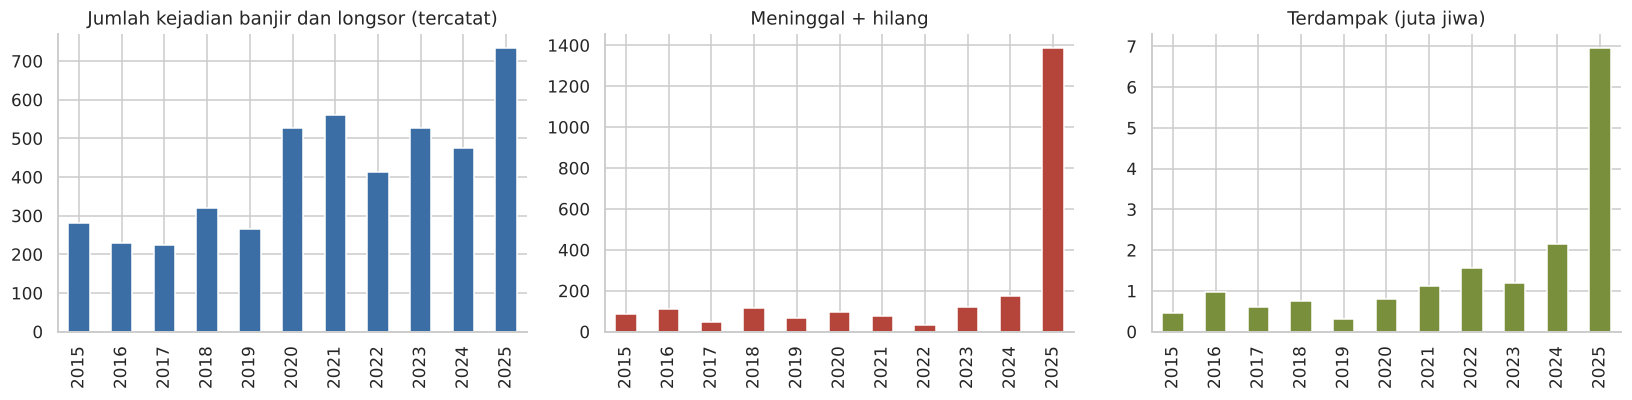

,kejadian,korban_jiwa,rr_berat,terdampak
provinsi,,,,
Sumatera Utara,893,705,7830,4673610
Aceh,880,675,55013,6667424
Sumatera Barat,703,584,5147,1054606
Bengkulu,228,92,462,269794
Lampung,318,64,771,463618
Kepulauan Riau,67,64,131,56559
Sumatera Selatan,524,48,873,1402116
Jambi,282,47,3074,752383
Kepulauan Bangka Belitung,112,26,0,66732


In [5]:
dib = m.groupby('tahun')[['kejadian','korban_jiwa','terdampak','rr_berat','sekolah_rusak','faskes_rusak','jembatan_rusak']].sum()
display(dib.astype(int))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
dib.kejadian.plot(kind='bar', ax=ax[0], color='#3b6ea5'); ax[0].set_title('Jumlah kejadian banjir dan longsor (tercatat)')
dib.korban_jiwa.plot(kind='bar', ax=ax[1], color='#b5453a'); ax[1].set_title('Meninggal + hilang')
(dib.terdampak/1e6).plot(kind='bar', ax=ax[2], color='#7a8f3c'); ax[2].set_title('Terdampak (juta jiwa)')
for a_ in ax: a_.set_xlabel('')
plt.tight_layout(); plt.show()
prov = m.groupby('provinsi')[['kejadian','korban_jiwa','rr_berat','terdampak']].sum().sort_values('korban_jiwa', ascending=False).astype(int)
display(prov)

In [6]:
k25 = int(dib.loc[2025,'korban_jiwa']); k_prev = dib.loc[2015:2024,'korban_jiwa'].mean()
t25 = dib.loc[2025,'terdampak']/1e6; t_prev = dib.loc[2015:2024,'terdampak'].mean()/1e6
display(Markdown(f'''**Interpretasi.** Pada 2025 DIBI mencatat **{k25:,} korban meninggal dan hilang** dan **{t25:.1f} juta jiwa terdampak** untuk banjir dan longsor di Sumatera, dibandingkan rata-rata 2015-2024 sebesar {k_prev:.0f} korban dan {t_prev:.2f} juta jiwa terdampak per tahun. Jumlah kejadian tercatat juga meningkat tajam sejak 2020. Sebagian peningkatan itu mencerminkan perbaikan pencatatan, bukan hanya kejadian fisik, sehingga fitur dan pengujian harus diperlakukan hati-hati (lihat bagian 13). Angka resmi korban dan kerugian yang dikutip di naskah harus bersumber dari rilis BNPB, bukan dari agregasi ini.'''))

**Interpretasi.** Pada 2025 DIBI mencatat **1,387 korban meninggal dan hilang** dan **7.0 juta jiwa terdampak** untuk banjir dan longsor di Sumatera, dibandingkan rata-rata 2015-2024 sebesar 93 korban dan 0.99 juta jiwa terdampak per tahun. Jumlah kejadian tercatat juga meningkat tajam sejak 2020. Sebagian peningkatan itu mencerminkan perbaikan pencatatan, bukan hanya kejadian fisik, sehingga fitur dan pengujian harus diperlakukan hati-hati (lihat bagian 13). Angka resmi korban dan kerugian yang dikutip di naskah harus bersumber dari rilis BNPB, bukan dari agregasi ini.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s5"></a>5. Variabel target dan uji sensitivitas ambang

Tidak ada ambang resmi BNPB untuk "keparahan" per kabupaten/kota-tahun. Definisi di sini disusun dari indikator dampak yang sama dengan **Kerangka Sendai (UNDRR)**: korban jiwa (Target A), kerusakan rumah (Target C), dan kerusakan infrastruktur kritis (Target D). Ambang dikunci memakai **hanya data latih (2015-2024)** agar tidak bocor ke data uji 2025.

> **y_berat = 1** jika dalam satu tahun di suatu kab/kota (banjir + longsor) terdapat **korban meninggal atau hilang >= 1**, **atau** jumlah **rumah rusak berat >= persentil 75** dari nilai positif data latih.

Kerusakan sekolah, puskesmas, dan jembatan sengaja **tidak** dimasukkan ke target. Ketiganya dipakai sebagai bukti validasi independen untuk indeks prioritas pada bagian 12.

,persentil,ambang rumah rusak berat,prevalensi 2015-2024,prevalensi 2025
0,0.50,4.0,0.239,0.416
1,0.75,13.0,0.192,0.344
2,0.90,42.0,0.173,0.325


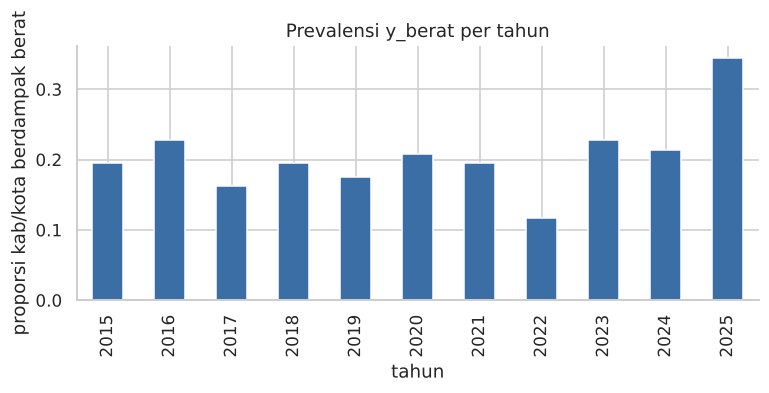

In [7]:
tr_all = m[m.tahun <= 2024]
pos = tr_all.rr_berat[tr_all.rr_berat > 0]
rows = []
for q in (0.50, 0.75, 0.90):
    th = pos.quantile(q)
    y_ = ((m.korban_jiwa >= 1) | (m.rr_berat >= th)).astype(int)
    rows.append({'persentil': q, 'ambang rumah rusak berat': th, 'prevalensi 2015-2024': y_[m.tahun<=2024].mean(), 'prevalensi 2025': y_[m.tahun==2025].mean()})
sens = pd.DataFrame(rows).round(3); display(sens)
TH = pos.quantile(0.75)
m['y'] = ((m.korban_jiwa >= 1) | (m.rr_berat >= TH)).astype(int)
prev = m.groupby('tahun').y.mean()
prev.plot(kind='bar', color='#3b6ea5', figsize=(8,3)); plt.ylabel('proporsi kab/kota berdampak berat'); plt.title('Prevalensi y_berat per tahun'); plt.show()

In [8]:
display(Markdown(f'''**Interpretasi.** Ambang rumah rusak berat (persentil 75 nilai positif data latih) adalah **{TH:.0f} unit**. Prevalensi y_berat rata-rata 2015-2024 sebesar **{m[m.tahun<=2024].y.mean():.1%}**, lalu naik menjadi **{prev.loc[2025]:.1%}** pada 2025. Perubahan persentil 50, 75, atau 90 hanya menggeser prevalensi sedikit, sehingga definisi ini tidak sangat peka terhadap pilihan ambang. Lonjakan 2025 adalah ciri data uji yang perlu diingat saat membaca kalibrasi model.'''))

**Interpretasi.** Ambang rumah rusak berat (persentil 75 nilai positif data latih) adalah **13 unit**. Prevalensi y_berat rata-rata 2015-2024 sebesar **19.2%**, lalu naik menjadi **34.4%** pada 2025. Perubahan persentil 50, 75, atau 90 hanya menggeser prevalensi sedikit, sehingga definisi ini tidak sangat peka terhadap pilihan ambang. Lonjakan 2025 adalah ciri data uji yang perlu diingat saat membaca kalibrasi model.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s6"></a>6. Rekayasa fitur dan eksplorasi data

In [9]:
g = m.groupby('kode_bps')
for c in ['hilang_hutan_frak', 'hilang_hutan_curam_frak', 'ndvi', 'A_t_tha']:
    m[c + '_l1'] = g[c].shift(1)
m['log_kepadatan'] = np.log(m.kepadatan_pddk)
# Catatan kebocoran: indikator hulu (loss_curam_hulu_frak, beban_erosi_hulu_t_km2) dihitung dari jendela 2015-2025,
# termasuk 2025 (bekas longsor 2025 tercatat sebagai kehilangan hutan). Karena itu TIDAK dipakai sebagai fitur model,
# hanya dianalisis deskriptif (bagian 7) dan sebagai kriteria pada indeks prioritas (bagian 12).

STATIS = ['elev_m','slope_deg','hand_m','frak_hand_lt5m','treecover2000','frak_lereng_curam','frak_hutan_curam_2000',
          'lc_10','lc_40','lc_50','lc_80','water_occ_gt0','sand_0_30','clay_0_30','silt_0_30','soc_0_30',
          'K_rusle','LS_rusle','A_rusle_median_tha','frak_erosi_gt60','log_kepadatan']
DINAMIS = ['hujan_mm','rx1day_mm','rx3day_mm','hari_ge50mm','hari_ge100mm','R_t',
           'hilang_hutan_frak_l1','hilang_hutan_curam_frak_l1','ndvi_l1','A_t_tha_l1']
KAPASITAS = ['ipm','p0','jalan_km_per_km2','puskesmas_per100k','rs_per100k']
FITUR = STATIS + DINAMIS          # model bahaya + eksposur
FITUR_SEMUA = FITUR + KAPASITAS   # pembanding

d = m[m.tahun >= 2017].dropna(subset=FITUR_SEMUA + ['y']).copy()
Xtr, Xte = d[d.tahun <= 2024], d[d.tahun == 2025]
print('Sampel model:', d.shape[0], '| latih:', len(Xtr), '(2017-2024) | uji:', len(Xte), '(2025)')
print('Prevalensi latih %.3f | uji %.3f' % (Xtr.y.mean(), Xte.y.mean()))

Sampel model: 1386 | latih: 1232 (2017-2024) | uji: 154 (2025)
Prevalensi latih 0.187 | uji 0.344


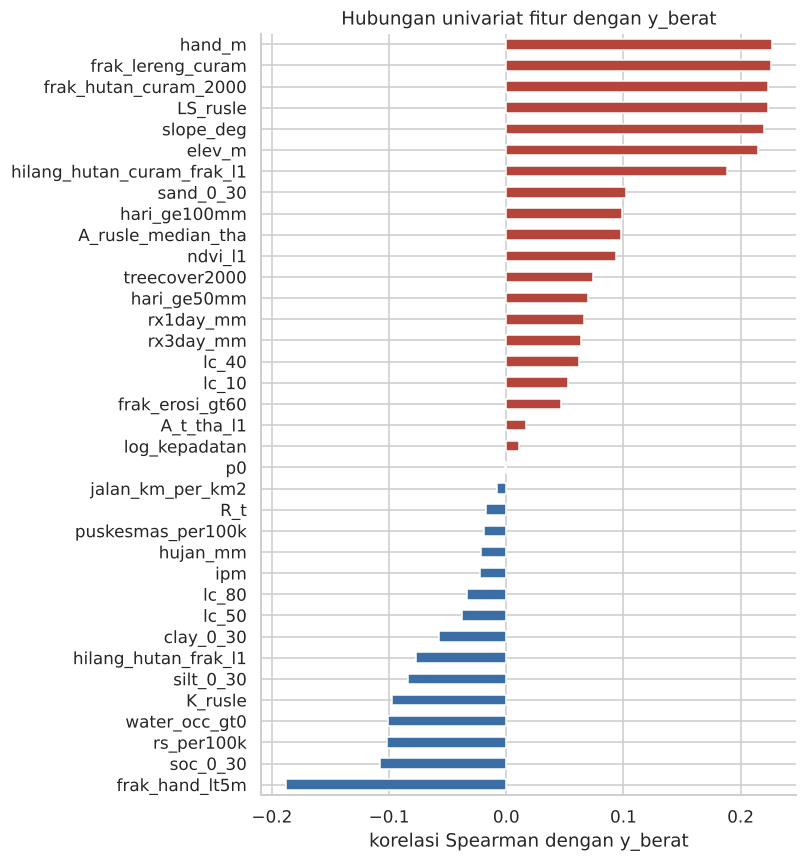

**Interpretasi.** Korelasi univariat terkuat: `hand_m` (+0.23); `frak_lereng_curam` (+0.23); `frak_hutan_curam_2000` (+0.22); `LS_rusle` (+0.22); `slope_deg` (+0.22); `elev_m` (+0.21). Korelasi ini bersifat asosiasi dan tidak menyatakan sebab-akibat. Variabel padat penduduk dan kapasitas layanan berkorelasi dengan y_berat sebagian karena wilayah berpenduduk padat lebih banyak memiliki rumah dan korban yang bisa tercatat (efek eksposur dan pelaporan).

In [10]:
rho = pd.Series({c: spearmanr(d[c], d.y)[0] for c in FITUR_SEMUA}).sort_values()
plt.figure(figsize=(7.5, 8)); rho.plot(kind='barh', color=np.where(rho > 0, '#b5453a', '#3b6ea5'))
plt.xlabel('korelasi Spearman dengan y_berat'); plt.title('Hubungan univariat fitur dengan y_berat'); plt.tight_layout(); plt.show()
top = rho.reindex(rho.abs().sort_values(ascending=False).index).head(6)
display(Markdown('**Interpretasi.** Korelasi univariat terkuat: ' + '; '.join(f'`{k}` ({v:+.2f})' for k, v in top.items()) + '. Korelasi ini bersifat asosiasi dan tidak menyatakan sebab-akibat. Variabel padat penduduk dan kapasitas layanan berkorelasi dengan y_berat sebagian karena wilayah berpenduduk padat lebih banyak memiliki rumah dan korban yang bisa tercatat (efek eksposur dan pelaporan).'))

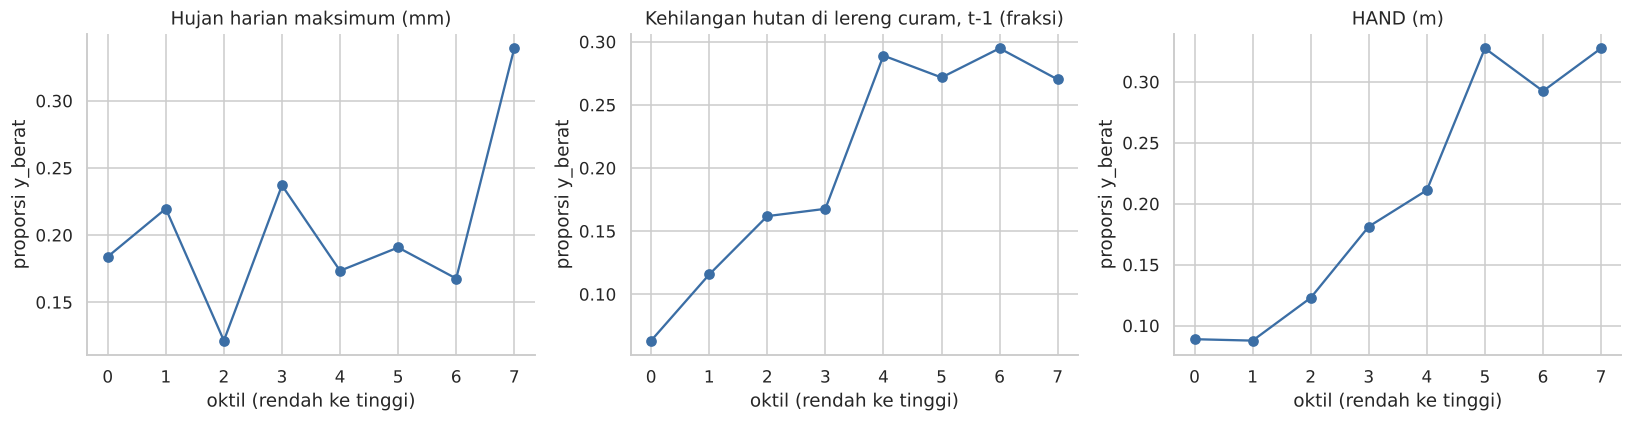

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, v, t in zip(ax, ['rx1day_mm','hilang_hutan_curam_frak_l1','hand_m'], ['Hujan harian maksimum (mm)','Kehilangan hutan di lereng curam, t-1 (fraksi)','HAND (m)']):
    tmp = d.assign(b=pd.qcut(d[v], 8, duplicates='drop')).groupby('b').y.mean()
    a_.plot(range(len(tmp)), tmp.values, marker='o', color='#3b6ea5'); a_.set_title(t); a_.set_xlabel('oktil (rendah ke tinggi)'); a_.set_ylabel('proporsi y_berat')
plt.tight_layout(); plt.show()

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

---
# Bagian II · Metode 1: Analisis hulu–hilir

**Hipotesis H1 dan H2.** Jika hilangnya hutan di lereng curam pada DAS hulu menambah limpasan dan material, maka indikator itu (diakumulasi sepanjang jaringan sub-DAS) berasosiasi positif dengan keparahan bencana di kab/kota hilir. Erosi RUSLE diuji dengan cara yang sama sebagai pembanding.

**Catatan kebocoran.** Indikator hulu memakai jendela 2015–2025 (memuat tahun uji) dan Hansen mencatat bekas longsor sebagai kehilangan hutan. Karena itu indikator hulu **tidak** menjadi fitur model di Bagian III, melainkan dianalisis di sini dan dipakai sebagai kriteria prioritas di Bagian IV.

## <a id="s7"></a>7. Metode 1: RUSLE terkoreksi dan tekanan lahan hulu per sub-DAS

Bagian ini menjawab pertanyaan **apakah kondisi lahan di hulu berkaitan dengan dampak bencana di kab/kota**. Ada dua komponen:

1. **RUSLE** (A = R × K × LS × C × P) memperkirakan **erosi lembar dan alur jangka panjang** (t/ha/th). RUSLE **bukan** model longsor atau banjir bandang; ia mengukur degradasi lahan kronis yang menyuplai sedimen ke sungai.
2. **Tekanan lahan hulu**: kehilangan hutan di lereng curam (> 15°) dan erosi RUSLE pada setiap sub-DAS HydroBASINS level 8 (693 sub-DAS) **diakumulasi mengikuti arah aliran** (kolom NEXT_DOWN) ke semua sub-DAS di hilirnya, lalu dirata-ratakan ke kab/kota menurut luas irisan.

**Perbaikan dibanding versi sebelumnya**: koefisien f_csand pada K dikoreksi (-0,0256; sebelumnya -0,256 sehingga K hampir konstan), R memakai persamaan Renard-Freimund (1994) bentuk lengkap untuk P > 850 mm, NDVI MODIS disaring kualitas, dan seluruh faktor dihitung pada piksel 90 m.

In [12]:
st = m.drop_duplicates('kode_bps').set_index('kode_bps')
fak = ['R_rusle', 'K_rusle', 'LS_rusle', 'C_rusle', 'A_rusle_tha', 'A_rusle_median_tha', 'A_rusle_p90_tha']
display(st[fak].describe().T[['min', '25%', '50%', '75%', 'max']].round(3))
# Faktor mana yang membedakan erosi antarwilayah? Simpangan baku log tiap faktor dan korelasinya dengan log A
L = np.log(st[['R_rusle', 'K_rusle', 'LS_rusle', 'C_rusle']]); la = np.log(st.A_rusle_tha)
dek = pd.DataFrame({'sd log faktor': L.std(), 'korelasi dengan log A': L.apply(lambda c: np.corrcoef(c, la)[0, 1])}).round(3)
display(dek)

,min,25%,50%,75%,max
R_rusle,7945.887,25989.657,30346.030,33603.366,62729.624
K_rusle,0.026,0.028,0.029,0.030,0.033
LS_rusle,0.053,0.746,2.881,5.970,14.467
C_rusle,0.000,0.003,0.008,0.023,0.249
A_rusle_tha,0.133,1.028,2.441,5.740,96.646
A_rusle_median_tha,0.031,0.286,0.617,1.137,23.272
A_rusle_p90_tha,0.031,0.417,1.015,4.903,279.109


,sd log faktor,korelasi dengan log A
R_rusle,0.289,-0.017
K_rusle,0.050,-0.071
LS_rusle,1.356,0.155
C_rusle,1.327,0.476


In [13]:
d_ = dek['sd log faktor']
display(Markdown(f'''**Interpretasi faktor.** Variasi antarwilayah paling besar berasal dari **C** (sd log {d_['C_rusle']:.2f}) dan **LS** (sd log {d_['LS_rusle']:.2f}), sedangkan K hampir seragam (sd log {d_['K_rusle']:.2f}) karena SoilGrids 250 m bersifat halus. Korelasi log C dengan log A ({dek.loc['C_rusle','korelasi dengan log A']:+.2f}) jauh lebih kuat daripada LS ({dek.loc['LS_rusle','korelasi dengan log A']:+.2f}). Di Sumatera, **lereng curam umumnya masih berhutan (C kecil), sedangkan lahan terbuka berada di dataran dan perbukitan landai**, sehingga erosi kab/kota terutama ditentukan oleh tutupan lahan. R berkisar {st.R_rusle.min():,.0f} sampai {st.R_rusle.max():,.0f} MJ mm ha-1 jam-1 th-1; nilai tertinggi berasal dari hujan tahunan sampai sekitar 4.000 mm, di luar rentang kalibrasi persamaan Renard-Freimund, sehingga **besaran absolut A bersifat indikatif dan yang diandalkan adalah peringkatnya**.'''))

**Interpretasi faktor.** Variasi antarwilayah paling besar berasal dari **C** (sd log 1.33) dan **LS** (sd log 1.36), sedangkan K hampir seragam (sd log 0.05) karena SoilGrids 250 m bersifat halus. Korelasi log C dengan log A (+0.48) jauh lebih kuat daripada LS (+0.15). Di Sumatera, **lereng curam umumnya masih berhutan (C kecil), sedangkan lahan terbuka berada di dataran dan perbukitan landai**, sehingga erosi kab/kota terutama ditentukan oleh tutupan lahan. R berkisar 7,946 sampai 62,730 MJ mm ha-1 jam-1 th-1; nilai tertinggi berasal dari hujan tahunan sampai sekitar 4.000 mm, di luar rentang kalibrasi persamaan Renard-Freimund, sehingga **besaran absolut A bersifat indikatif dan yang diandalkan adalah peringkatnya**.

In [14]:
# Rerata vs median vs p90: rerata sangat dipengaruhi segelintir piksel ekstrem
cmp = st[['nama', 'provinsi', 'A_rusle_tha', 'A_rusle_median_tha', 'A_rusle_p90_tha', 'C_rusle', 'LS_rusle', 'lc_10', 'lc_30', 'lc_50', 'lc_60']]
print('10 teratas menurut MEDIAN piksel (dipakai sebagai ukuran utama):')
display(cmp.sort_values('A_rusle_median_tha', ascending=False).head(10).round(3))
print('Aceh (provinsi dengan dampak terbesar 2025):')
display(cmp[cmp.provinsi == 'Aceh'].sort_values('A_rusle_median_tha', ascending=False).head(8).round(3))

10 teratas menurut MEDIAN piksel (dipakai sebagai ukuran utama):


,nama,provinsi,A_rusle_tha,A_rusle_median_tha,A_rusle_p90_tha,C_rusle,LS_rusle,lc_10,lc_30,lc_50,lc_60
kode_bps,,,,,,,,,,,
2172,Kota Tanjung Pinang,Kepulauan Riau,96.646,23.272,279.109,0.139,0.836,0.363,0.210,0.146,0.089
1211,Kabupaten Karo,Sumatera Utara,48.053,10.258,10.258,0.012,7.218,0.713,0.143,0.014,0.006
1872,Kota Metro,Lampung,15.708,6.991,44.938,0.090,0.451,0.295,0.010,0.341,0.001
1374,Kota Padang Panjang,Sumatera Barat,13.469,5.989,33.773,0.045,4.834,0.552,0.022,0.226,0.001
1375,Kota Bukittinggi,Sumatera Barat,21.961,5.936,45.910,0.126,2.626,0.388,0.047,0.428,0.002
2171,Kota Batam,Kepulauan Riau,50.254,5.044,110.807,0.101,1.406,0.494,0.116,0.109,0.045
1273,Kota Pematang Siantar,Sumatera Utara,15.800,4.905,47.004,0.074,0.862,0.499,0.056,0.286,0.005
2102,Kabupaten Bintan,Kepulauan Riau,23.482,3.997,45.425,0.041,1.255,0.608,0.212,0.012,0.029
1810,Kabupaten Pringsewu,Lampung,8.518,3.830,3.830,0.030,2.568,0.658,0.015,0.078,0.001


Aceh (provinsi dengan dampak terbesar 2025):


,nama,provinsi,A_rusle_tha,A_rusle_median_tha,A_rusle_p90_tha,C_rusle,LS_rusle,lc_10,lc_30,lc_50,lc_60
kode_bps,,,,,,,,,,,
1108,Kabupaten Aceh Besar,Aceh,5.143,1.814,1.814,0.013,7.399,0.776,0.137,0.015,0.004
1113,Kabupaten Gayo Lues,Aceh,2.530,1.459,1.459,0.001,14.467,0.934,0.056,0.001,0.001
1102,Kabupaten Aceh Singkil,Aceh,2.786,1.185,1.185,0.007,1.541,0.861,0.067,0.004,0.001
1106,Kabupaten Aceh Tengah,Aceh,5.160,1.002,1.002,0.008,11.975,0.908,0.069,0.004,0.000
1171,Kota Banda Aceh,Aceh,1.950,0.841,6.841,0.231,0.134,0.200,0.078,0.548,0.010
1172,Kota Sabang,Aceh,8.310,0.698,0.698,0.007,8.623,0.904,0.012,0.025,0.001
1109,Kabupaten Pidie,Aceh,1.609,0.502,0.502,0.012,8.625,0.863,0.033,0.011,0.002
1115,Kabupaten Nagan Raya,Aceh,1.654,0.476,0.476,0.004,6.833,0.941,0.027,0.004,0.002


In [15]:
tp = st.loc[st.nama == 'Kota Tanjung Pinang'].iloc[0]; med = st[['lc_10', 'lc_30', 'lc_60', 'C_rusle']].median()
aceh = st[st.provinsi == 'Aceh']
display(Markdown(f'''**Interpretasi peringkat.** Kota Tanjung Pinang berada di puncak (median {tp.A_rusle_median_tha:.1f} t/ha/th, p90 {tp.A_rusle_p90_tha:.0f}) karena tutupan pohonnya hanya {tp.lc_10:.0%} (median Sumatera {med.lc_10:.0%}) dengan rumput/semak {tp.lc_30:.0%} dan lahan terbuka {tp.lc_60:.0%} (median {med.lc_60:.1%}), di bawah hujan rata-rata tinggi. Nilai C-nya {tp.C_rusle:.3f}, sekitar {tp.C_rusle/med.C_rusle:.0f} kali median. Ini **erosi akibat lahan terbuka di kota pulau**, dan tidak berkaitan dengan mekanisme banjir bandang di pegunungan Bukit Barisan. Sebaliknya, median erosi kab/kota di Aceh ({aceh.A_rusle_median_tha.median():.2f} t/ha/th) lebih rendah dari median Sumatera ({st.A_rusle_median_tha.median():.2f}) karena hulu Aceh **masih relatif berhutan**. Jadi erosi lembar/alur kronis **bukan pembeda utama** keparahan bencana; hal ini diuji langsung di sel berikut.'''))

**Interpretasi peringkat.** Kota Tanjung Pinang berada di puncak (median 23.3 t/ha/th, p90 279) karena tutupan pohonnya hanya 36% (median Sumatera 86%) dengan rumput/semak 21% dan lahan terbuka 9% (median 0.1%), di bawah hujan rata-rata tinggi. Nilai C-nya 0.139, sekitar 17 kali median. Ini **erosi akibat lahan terbuka di kota pulau**, dan tidak berkaitan dengan mekanisme banjir bandang di pegunungan Bukit Barisan. Sebaliknya, median erosi kab/kota di Aceh (0.36 t/ha/th) lebih rendah dari median Sumatera (0.62) karena hulu Aceh **masih relatif berhutan**. Jadi erosi lembar/alur kronis **bukan pembeda utama** keparahan bencana; hal ini diuji langsung di sel berikut.

In [16]:
# Hubungan indikator lahan dengan keparahan bencana
ya = m[m.tahun <= 2024].groupby('kode_bps').y.mean()
e25 = m[m.tahun == 2025].set_index('kode_bps')
ind = {'A_rusle_median_tha': 'Erosi RUSLE lokal (median)', 'A_rusle_tha': 'Erosi RUSLE lokal (rerata)',
       'beban_erosi_hulu_t_km2': 'Beban erosi hulu per km2 DAS', 'loss_curam_hulu_frak': 'Kehilangan hutan lereng curam di hulu (fraksi DAS)',
       'hilang_hutan_curam_frak': 'Kehilangan hutan lereng curam lokal', 'frak_hutan_curam_2000': 'Hutan lereng curam 2000 (lokal)', 'slope_deg': 'Kemiringan rata-rata'}
rows = []
for c, lab in ind.items():
    x = m.groupby('kode_bps')[c].mean()
    rows.append([lab, spearmanr(x, ya.reindex(x.index))[0], spearmanr(x, e25.korban_jiwa.reindex(x.index))[0], spearmanr(x, e25.rr_berat.reindex(x.index))[0]])
hub = pd.DataFrame(rows, columns=['indikator', 'rho vs frekuensi y_berat 2015-2024', 'rho vs korban jiwa 2025', 'rho vs rumah rusak berat 2025']).round(2)
display(hub)

,indikator,rho vs frekuensi y_berat 2015-2024,rho vs korban jiwa 2025,rho vs rumah rusak berat 2025
0,Erosi RUSLE lokal (median),0.32,-0.07,-0.03
1,Erosi RUSLE lokal (rerata),0.12,0.03,-0.06
2,Beban erosi hulu per km2 DAS,0.21,0.11,0.03
3,Kehilangan hutan lereng curam di hulu (fraksi DAS),0.53,0.25,0.38
4,Kehilangan hutan lereng curam lokal,0.50,0.19,0.23
5,Hutan lereng curam 2000 (lokal),0.56,0.23,0.33
6,Kemiringan rata-rata,0.54,0.22,0.32


In [17]:
# Frekuensi kejadian berat per kuartil tekanan hulu dan 10 kab/kota dengan tekanan hulu tertinggi
th_ = st[['nama', 'provinsi', 'loss_curam_hulu_frak']].assign(frek_berat=ya.reindex(st.index))
th_['kuartil_tekanan_hulu'] = pd.qcut(th_.loss_curam_hulu_frak, 4, labels=['Q1 rendah', 'Q2', 'Q3', 'Q4 tinggi'])
display(th_.groupby('kuartil_tekanan_hulu', observed=True).frek_berat.agg(['count', 'mean']).rename(columns={'count': 'kab/kota', 'mean': 'frekuensi tahun berdampak berat'}).round(3))
display(th_.assign(persen_DAS_hulu=100 * th_.loss_curam_hulu_frak).sort_values('persen_DAS_hulu', ascending=False)[['nama', 'provinsi', 'persen_DAS_hulu']].head(10).round(2))

,kab/kota,frekuensi tahun berdampak berat
kuartil_tekanan_hulu,,
Q1 rendah,39,0.077
Q2,38,0.139
Q3,38,0.234
Q4 tinggi,39,0.315


,nama,provinsi,persen_DAS_hulu
kode_bps,,,
1117,Kabupaten Bener Meriah,Aceh,6.71
1113,Kabupaten Gayo Lues,Aceh,6.33
1106,Kabupaten Aceh Tengah,Aceh,6.07
1371,Kota Padang,Sumatera Barat,5.63
1210,Kabupaten Dairi,Sumatera Utara,5.10
1309,Kabupaten Pasaman,Sumatera Barat,5.02
1501,Kabupaten Kerinci,Jambi,4.88
1572,Kota Sungai Penuh,Jambi,4.85
1304,Kabupaten Sijunjung,Sumatera Barat,4.63


In [18]:
h = hub.set_index('indikator')
display(Markdown(f'''**Interpretasi hulu-hilir.** Erosi RUSLE lokal hanya berasosiasi lemah dengan frekuensi kejadian berat (rho median {h.loc['Erosi RUSLE lokal (median)','rho vs frekuensi y_berat 2015-2024']:+.2f}), sedangkan **kehilangan hutan di lereng curam di hulu** berasosiasi jauh lebih kuat (rho {h.loc['Kehilangan hutan lereng curam di hulu (fraksi DAS)','rho vs frekuensi y_berat 2015-2024']:+.2f}) dan juga dengan rumah rusak berat 2025 (rho {h.loc['Kehilangan hutan lereng curam di hulu (fraksi DAS)','rho vs rumah rusak berat 2025']:+.2f}). Kemiringan dan keberadaan hutan di lereng curam (penanda wilayah pegunungan) juga kuat. Pesan untuk naskah: **yang membedakan wilayah berdampak berat bukan erosi permukaan kronis, melainkan kombinasi medan curam dan hilangnya hutan di lereng curam pada DAS hulu**. Ada dua peringatan: (1) Hansen mencatat bekas longsor sebagai kehilangan hutan, sehingga sebagian asosiasi bisa berarah terbalik (bencana menyebabkan hilangnya tutupan); (2) jendela 2015-2025 memuat tahun kejadian, karena itu indikator hulu tidak dipakai sebagai fitur model prediktif.'''))

**Interpretasi hulu-hilir.** Erosi RUSLE lokal hanya berasosiasi lemah dengan frekuensi kejadian berat (rho median +0.32), sedangkan **kehilangan hutan di lereng curam di hulu** berasosiasi jauh lebih kuat (rho +0.53) dan juga dengan rumah rusak berat 2025 (rho +0.38). Kemiringan dan keberadaan hutan di lereng curam (penanda wilayah pegunungan) juga kuat. Pesan untuk naskah: **yang membedakan wilayah berdampak berat bukan erosi permukaan kronis, melainkan kombinasi medan curam dan hilangnya hutan di lereng curam pada DAS hulu**. Ada dua peringatan: (1) Hansen mencatat bekas longsor sebagai kehilangan hutan, sehingga sebagian asosiasi bisa berarah terbalik (bencana menyebabkan hilangnya tutupan); (2) jendela 2015-2025 memuat tahun kejadian, karena itu indikator hulu tidak dipakai sebagai fitur model prediktif.

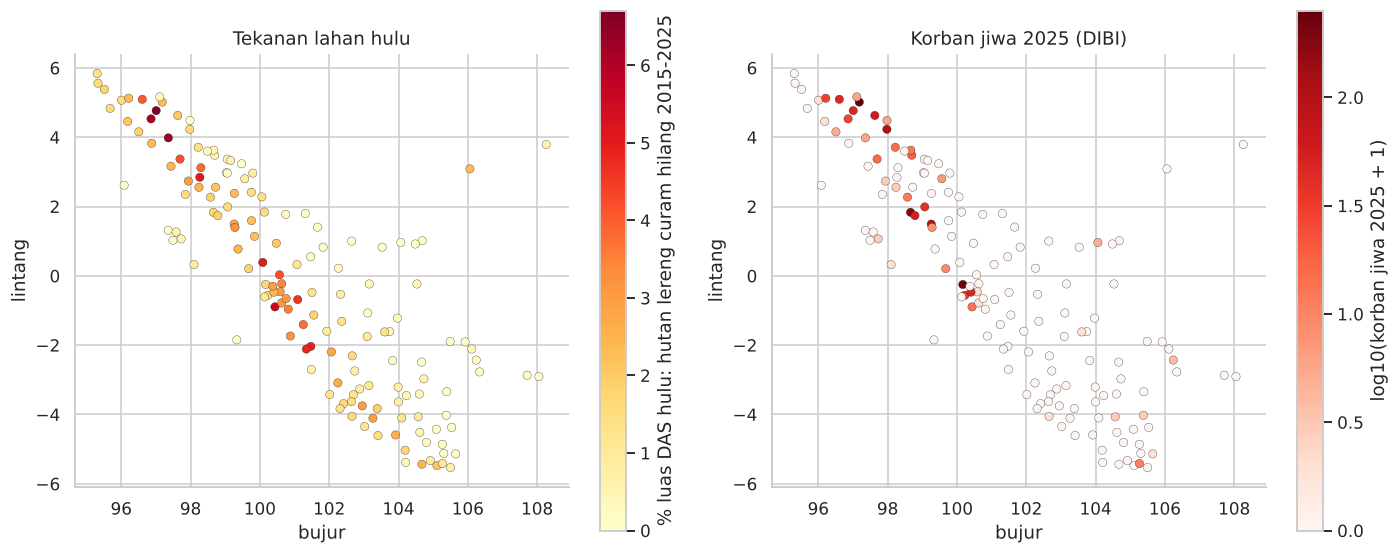

In [19]:
# Peta titik (pusat kab/kota): tekanan hulu vs dampak 2025
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
s1 = ax[0].scatter(st.centroid_lon, st.centroid_lat, c=st.loss_curam_hulu_frak * 100, cmap='YlOrRd', s=30, edgecolor='k', linewidth=.2)
plt.colorbar(s1, ax=ax[0], label='% luas DAS hulu: hutan lereng curam hilang 2015-2025'); ax[0].set_title('Tekanan lahan hulu')
s2 = ax[1].scatter(st.centroid_lon, st.centroid_lat, c=np.log10(e25.korban_jiwa.reindex(st.index) + 1), cmap='Reds', s=30, edgecolor='k', linewidth=.2)
plt.colorbar(s2, ax=ax[1], label='log10(korban jiwa 2025 + 1)'); ax[1].set_title('Korban jiwa 2025 (DIBI)')
for a_ in ax: a_.set_xlabel('bujur'); a_.set_ylabel('lintang'); a_.set_aspect('equal')
plt.tight_layout(); plt.show()

In [20]:
# Sub-DAS dengan tekanan hulu tertinggi (rujukan prioritas rehabilitasi hulu)
sd = pd.read_csv(SUBDAS)
sd['loss_hulu_persen'] = 100 * sd.loss_hulu_km2 / sd.UP_AREA
print('Jumlah sub-DAS:', len(sd), '| luas rata-rata %.0f km2' % sd.SUB_AREA.mean())
# satu baris per DAS utama (MAIN_BAS): sub-DAS dengan persentase kehilangan hutan hulu tertinggi, DAS hulu minimal 500 km2
top_sd = sd[sd.UP_AREA >= 500].sort_values('loss_hulu_persen', ascending=False).drop_duplicates('MAIN_BAS')
display(top_sd[['HYBAS_ID', 'MAIN_BAS', 'UP_AREA', 'loss_hulu_km2', 'loss_hulu_persen', 'A_tha']].head(10).round(2))
display(Markdown('**Catatan metode.** Beban erosi hulu mengasumsikan seluruh tanah tererosi terangkut ke hilir (rasio pelepasan sedimen = 1), sehingga merupakan **indeks tekanan**, bukan hasil sedimen terukur. HydroBASINS level 8 cukup kasar untuk DAS kecil di pesisir barat, dan kab/kota yang terpotong beberapa sub-DAS mendapat nilai rata-rata tertimbang luas.'))

Jumlah sub-DAS: 693 | luas rata-rata 697 km2


,HYBAS_ID,MAIN_BAS,UP_AREA,loss_hulu_km2,loss_hulu_persen,A_tha
9,5080125430,5080002210,1358.8,145.84,10.73,6.36
406,5080145600,5080003690,906.4,86.51,9.54,1.46
543,5080167830,5080004800,723.9,62.14,8.58,3.77
16,5080123570,5080002940,762.6,64.98,8.52,0.91
77,5080002840,5080002840,2342.8,198.49,8.47,1.49
0,5080127200,5080001960,1641.0,118.81,7.24,0.77
353,5080139970,5080001700,514.4,35.32,6.87,0.46
26,5080125160,5080003070,734.2,49.88,6.79,0.90
302,5080005710,5080005710,647.3,38.55,5.96,2.92
196,5080001130,5080001130,3068.8,173.27,5.65,5.54


**Catatan metode.** Beban erosi hulu mengasumsikan seluruh tanah tererosi terangkut ke hilir (rasio pelepasan sedimen = 1), sehingga merupakan **indeks tekanan**, bukan hasil sedimen terukur. HydroBASINS level 8 cukup kasar untuk DAS kecil di pesisir barat, dan kab/kota yang terpotong beberapa sub-DAS mendapat nilai rata-rata tertimbang luas.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

---
# Bagian III · Metode 2: Pembelajaran mesin dan penjelasan model

**Hipotesis H3–H6.** Model dilatih 2017–2024 dan diuji 2025 (H3), diuji pada blok wilayah baru (H4), dijelaskan dengan SHAP yang diuji terhadap fitur plasebo (H5), dan dilengkapi validasi kejadian 2025 (H6).

## <a id="s8"></a>8. Metode 2a: Pemodelan dengan validasi temporal (latih 2017–2024, uji 2025)

Skema: **latih 2017–2024, uji 2025 (out-of-time)**. Pemisahan acak per baris tidak dipakai karena kab/kota yang sama muncul di data latih dan uji (kebocoran spasial dan temporal). Pembanding yang wajib dikalahkan: **riwayat kejadian kab/kota** (proporsi tahun berdampak berat di data latih).

In [21]:
def xgb_model(**kw):
    p = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=3, random_state=SEED, eval_metric='logloss', n_jobs=1)
    p.update(kw); return xgb.XGBClassifier(**p)

modelos = {
 'Regresi logistik': make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000)),
 'Random forest': RandomForestClassifier(500, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
 'XGBoost': xgb_model(),
}
hasil, pred = [], {}
rate = Xtr.groupby('kode_bps').y.mean()
p0 = Xte.kode_bps.map(rate).fillna(Xtr.y.mean()).values
pred['Riwayat kab/kota (pembanding)'] = p0
hasil.append(['Riwayat kab/kota (pembanding)', roc_auc_score(Xte.y, p0), average_precision_score(Xte.y, p0), brier_score_loss(Xte.y, p0)])
for nm, mod in modelos.items():
    mod.fit(Xtr[FITUR], Xtr.y); p = mod.predict_proba(Xte[FITUR])[:, 1]; pred[nm] = p
    hasil.append([nm, roc_auc_score(Xte.y, p), average_precision_score(Xte.y, p), brier_score_loss(Xte.y, p)])
tabel = pd.DataFrame(hasil, columns=['model', 'ROC-AUC', 'AUC-PR', 'Brier']).round(3)
tabel.loc[len(tabel)] = ['(acuan prevalensi uji)', 0.5, round(Xte.y.mean(), 3), round(Xte.y.mean()*(1-Xte.y.mean()), 3)]
display(tabel)

,model,ROC-AUC,AUC-PR,Brier
0,Riwayat kab/kota (pembanding),0.658,0.479,0.239
1,Regresi logistik,0.703,0.572,0.218
2,Random forest,0.702,0.542,0.225
3,XGBoost,0.708,0.580,0.228
4,(acuan prevalensi uji),0.500,0.344,0.226


In [22]:
# Selang kepercayaan bootstrap (resampling kab/kota) untuk AUC-PR dan ROC-AUC
rng = np.random.default_rng(SEED); ids = Xte.kode_bps.values; yv = Xte.y.values
def boot(p, B=1000):
    a1, a2 = [], []
    for _ in range(B):
        ix = rng.integers(0, len(yv), len(yv))
        if yv[ix].min() == yv[ix].max(): continue
        a1.append(roc_auc_score(yv[ix], p[ix])); a2.append(average_precision_score(yv[ix], p[ix]))
    return np.percentile(a1, [2.5, 97.5]), np.percentile(a2, [2.5, 97.5])
ci = []
for nm, p in pred.items():
    a, b = boot(p); ci.append([nm, f'{a[0]:.2f}-{a[1]:.2f}', f'{b[0]:.2f}-{b[1]:.2f}'])
display(pd.DataFrame(ci, columns=['model', 'ROC-AUC (95% CI)', 'AUC-PR (95% CI)']))

,model,ROC-AUC (95% CI),AUC-PR (95% CI)
0,Riwayat kab/kota (pembanding),0.56-0.75,0.36-0.61
1,Regresi logistik,0.62-0.79,0.44-0.70
2,Random forest,0.61-0.79,0.43-0.69
3,XGBoost,0.62-0.80,0.45-0.72


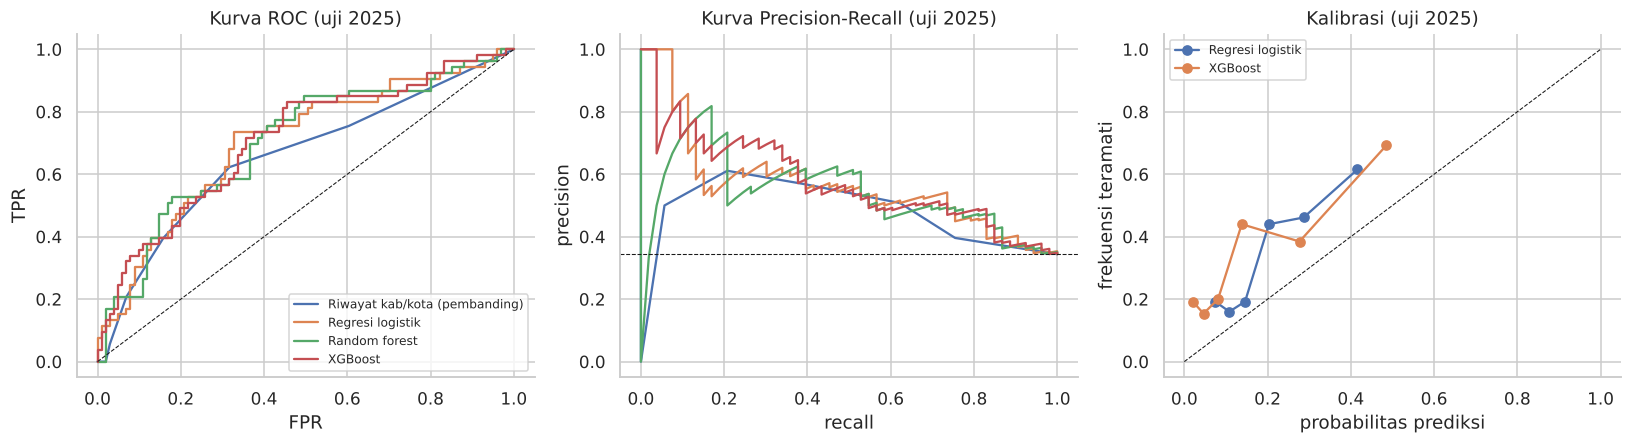

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for nm, p in pred.items():
    f, t, _ = roc_curve(Xte.y, p); ax[0].plot(f, t, label=nm)
    pr, rc, _ = precision_recall_curve(Xte.y, p); ax[1].plot(rc, pr, label=nm)
ax[0].plot([0,1],[0,1],'k--',lw=.7); ax[0].set_title('Kurva ROC (uji 2025)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(fontsize=8)
ax[1].axhline(Xte.y.mean(), color='k', ls='--', lw=.7); ax[1].set_title('Kurva Precision-Recall (uji 2025)'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision')
for nm in ['Regresi logistik', 'XGBoost']:
    fr, mp = calibration_curve(Xte.y, pred[nm], n_bins=6, strategy='quantile'); ax[2].plot(mp, fr, marker='o', label=nm)
ax[2].plot([0,1],[0,1],'k--',lw=.7); ax[2].set_title('Kalibrasi (uji 2025)'); ax[2].set_xlabel('probabilitas prediksi'); ax[2].set_ylabel('frekuensi teramati'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [24]:
best = tabel.iloc[1:4].sort_values('AUC-PR', ascending=False).iloc[0]
base = tabel.iloc[0]
mean_pred = {k: v.mean() for k, v in pred.items() if 'pembanding' not in k}
display(Markdown(f'''**Interpretasi.** Model terbaik pada uji 2025 adalah **{best.model}** (ROC-AUC {best['ROC-AUC']:.2f}; AUC-PR {best['AUC-PR']:.2f}), dibandingkan pembanding riwayat kab/kota (ROC-AUC {base['ROC-AUC']:.2f}; AUC-PR {base['AUC-PR']:.2f}) dan prevalensi uji {Xte.y.mean():.2f}. Kemampuan membedakan kab/kota berdampak berat **berada pada tingkat sedang, bukan tinggi**, dan selang kepercayaan cukup lebar karena hanya {len(Xte)} kab/kota diuji. Rata-rata probabilitas prediksi 2025 ({', '.join(f'{k}: {v:.2f}' for k, v in mean_pred.items())}) berada jauh di bawah prevalensi teramati ({Xte.y.mean():.2f}). Artinya fitur tingkat tahunan menangkap **kerentanan relatif antarwilayah**, tetapi tidak menangkap besarnya peristiwa hujan ekstrem tunggal 2025. Hal ini dikaji pada bagian 11.'''))

**Interpretasi.** Model terbaik pada uji 2025 adalah **XGBoost** (ROC-AUC 0.71; AUC-PR 0.58), dibandingkan pembanding riwayat kab/kota (ROC-AUC 0.66; AUC-PR 0.48) dan prevalensi uji 0.34. Kemampuan membedakan kab/kota berdampak berat **berada pada tingkat sedang, bukan tinggi**, dan selang kepercayaan cukup lebar karena hanya 154 kab/kota diuji. Rata-rata probabilitas prediksi 2025 (Regresi logistik: 0.21, Random forest: 0.20, XGBoost: 0.18) berada jauh di bawah prevalensi teramati (0.34). Artinya fitur tingkat tahunan menangkap **kerentanan relatif antarwilayah**, tetapi tidak menangkap besarnya peristiwa hujan ekstrem tunggal 2025. Hal ini dikaji pada bagian 11.

In [25]:
# Peran kelompok fitur (XGBoost, uji 2025)
def skor(cols):
    mod = xgb_model().fit(Xtr[cols], Xtr.y); p = mod.predict_proba(Xte[cols])[:, 1]
    return [roc_auc_score(Xte.y, p), average_precision_score(Xte.y, p)]
abl = pd.DataFrame({'statis saja': skor(STATIS), 'dinamis saja': skor(DINAMIS), 'bahaya + eksposur': skor(FITUR), '+ kapasitas dan sosial-ekonomi': skor(FITUR_SEMUA)}, index=['ROC-AUC', 'AUC-PR']).T.round(3)
display(abl)
display(Markdown('**Interpretasi.** Variabel kapasitas layanan dan sosial-ekonomi **tidak dimasukkan ke model bahaya** karena merupakan komponen kerentanan dan kapasitas, bukan penyebab fisik banjir atau longsor. Variabel itu dipakai terpisah pada indeks prioritas (bagian 12). Perbandingan di atas hanya untuk memeriksa apakah ada informasi tambahan yang hilang.'))

,ROC-AUC,AUC-PR
statis saja,0.662,0.496
dinamis saja,0.624,0.527
bahaya + eksposur,0.708,0.580
+ kapasitas dan sosial-ekonomi,0.696,0.566


**Interpretasi.** Variabel kapasitas layanan dan sosial-ekonomi **tidak dimasukkan ke model bahaya** karena merupakan komponen kerentanan dan kapasitas, bukan penyebab fisik banjir atau longsor. Variabel itu dipakai terpisah pada indeks prioritas (bagian 12). Perbandingan di atas hanya untuk memeriksa apakah ada informasi tambahan yang hilang.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s9"></a>9. Metode 2b: Uji ketahanan dengan validasi silang blok spasial

,blok uji,kab/kota,AUC XGBoost,AUC logit,AUC-PR XGBoost,prevalensi
0,5,35,0.633,0.640,0.315,0.214
1,1,33,0.709,0.624,0.380,0.239
2,0,32,0.705,0.640,0.329,0.180
3,2,28,0.618,0.591,0.167,0.121
4,3,19,0.463,0.532,0.168,0.178
5,4,7,0.309,0.589,0.121,0.125


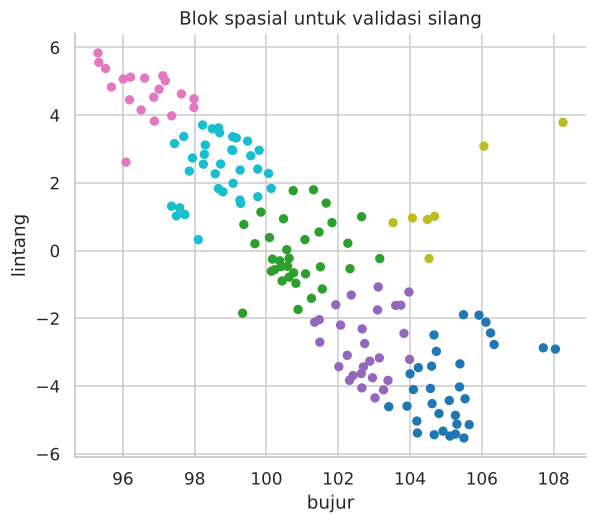

In [26]:
cent = m.drop_duplicates('kode_bps')[['kode_bps', 'centroid_lon', 'centroid_lat']].copy()
cent['blok'] = KMeans(6, random_state=SEED, n_init=10).fit_predict(cent[['centroid_lon', 'centroid_lat']])
Xs = Xtr.merge(cent[['kode_bps', 'blok']], on='kode_bps')
rs = []
for k, (a, b) in enumerate(GroupKFold(6).split(Xs, groups=Xs.blok)):
    mod = xgb_model().fit(Xs.iloc[a][FITUR], Xs.iloc[a].y); q = mod.predict_proba(Xs.iloc[b][FITUR])[:, 1]
    mod2 = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000)).fit(Xs.iloc[a][FITUR], Xs.iloc[a].y); q2 = mod2.predict_proba(Xs.iloc[b][FITUR])[:, 1]
    rs.append({'blok uji': int(Xs.iloc[b].blok.iloc[0]), 'kab/kota': Xs.iloc[b].kode_bps.nunique(), 'AUC XGBoost': roc_auc_score(Xs.iloc[b].y, q), 'AUC logit': roc_auc_score(Xs.iloc[b].y, q2), 'AUC-PR XGBoost': average_precision_score(Xs.iloc[b].y, q), 'prevalensi': Xs.iloc[b].y.mean()})
cv = pd.DataFrame(rs).round(3); display(cv)
fig, ax = plt.subplots(figsize=(6, 5)); sc = ax.scatter(cent.centroid_lon, cent.centroid_lat, c=cent.blok, cmap='tab10', s=26); ax.set_title('Blok spasial untuk validasi silang'); ax.set_xlabel('bujur'); ax.set_ylabel('lintang'); plt.show()

In [27]:
display(Markdown(f'''**Interpretasi.** Saat model diuji pada blok wilayah yang **tidak pernah dilihat saat pelatihan**, rata-rata ROC-AUC XGBoost turun menjadi **{cv['AUC XGBoost'].mean():.2f}** (logistik {cv['AUC logit'].mean():.2f}), dengan rentang {cv['AUC XGBoost'].min():.2f} sampai {cv['AUC XGBoost'].max():.2f} antarblok. Penurunan ini menunjukkan bahwa sebagian kemampuan prediksi pada uji temporal berasal dari **kekhasan lokal kab/kota** (pola pelaporan dan karakter lahan) yang tidak dapat dipindahkan begitu saja ke wilayah lain. Model ini layak dipakai untuk **memeringkat kerentanan dan menafsirkan faktor**, tetapi bukan untuk peramalan operasional kab/kota baru.'''))

**Interpretasi.** Saat model diuji pada blok wilayah yang **tidak pernah dilihat saat pelatihan**, rata-rata ROC-AUC XGBoost turun menjadi **0.57** (logistik 0.60), dengan rentang 0.31 sampai 0.71 antarblok. Penurunan ini menunjukkan bahwa sebagian kemampuan prediksi pada uji temporal berasal dari **kekhasan lokal kab/kota** (pola pelaporan dan karakter lahan) yang tidak dapat dipindahkan begitu saja ke wilayah lain. Model ini layak dipakai untuk **memeringkat kerentanan dan menafsirkan faktor**, tetapi bukan untuk peramalan operasional kab/kota baru.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s10"></a>10. Metode 2c: Interpretasi model (SHAP, uji plasebo, profil respons)

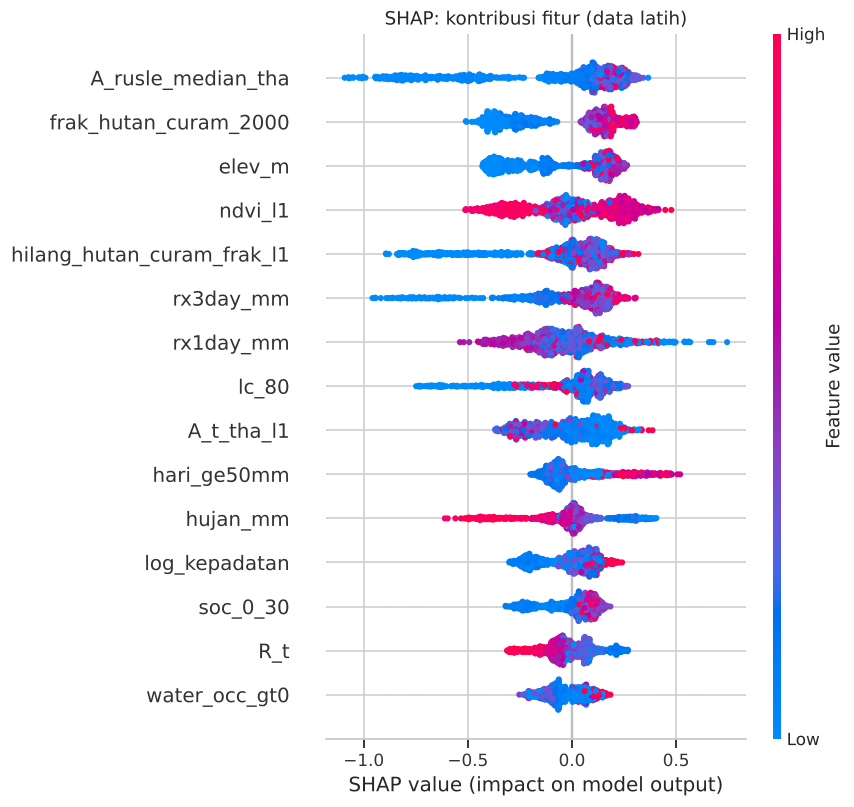

,rata-rata |SHAP|
A_rusle_median_tha,0.277
frak_hutan_curam_2000,0.225
elev_m,0.214
ndvi_l1,0.181
hilang_hutan_curam_frak_l1,0.179
rx3day_mm,0.161
rx1day_mm,0.145
lc_80,0.144
A_t_tha_l1,0.139
hari_ge50mm,0.113


In [28]:
final = xgb_model().fit(Xtr[FITUR], Xtr.y)
expl = shap.TreeExplainer(final); sv = expl.shap_values(Xtr[FITUR])
imp = pd.Series(np.abs(sv).mean(0), index=FITUR).sort_values(ascending=False)
plt.figure(); shap.summary_plot(sv, Xtr[FITUR], max_display=15, show=False); plt.title('SHAP: kontribusi fitur (data latih)'); plt.tight_layout(); plt.show()
display(imp.head(10).round(3).to_frame('rata-rata |SHAP|'))

In [29]:
# Uji plasebo: tambahkan satu fitur ACAK yang tetap per kab/kota (tidak bermakna fisik), diulang 10 kali.
# Fitur statis bernilai unik per kab/kota bisa dipakai model sebagai 'identitas wilayah' untuk menghafal riwayatnya.
# |SHAP| plasebo tertinggi dari 10 ulangan menjadi batas bawah untuk menafsirkan fitur STATIS.
plas = []
for r_ in range(10):
    acak = pd.Series(np.random.default_rng(100 + r_).random(m.kode_bps.nunique()), index=m.kode_bps.unique())
    Xp = Xtr.assign(acak_statis=Xtr.kode_bps.map(acak)); Fp = FITUR + ['acak_statis']
    mp = xgb_model().fit(Xp[Fp], Xp.y)
    ip = pd.Series(np.abs(shap.TreeExplainer(mp).shap_values(Xp[Fp])).mean(0), index=Fp)
    plas.append((ip['acak_statis'], int((ip > ip['acak_statis']).sum()) + 1))
plas = pd.DataFrame(plas, columns=['shap_plasebo', 'peringkat_plasebo'])
batas = plas.shap_plasebo.max()
print('Plasebo |SHAP|: rerata %.3f, maks %.3f | peringkat median %d dari %d' % (plas.shap_plasebo.mean(), batas, plas.peringkat_plasebo.median(), len(FITUR) + 1))
tab_imp = imp.to_frame('|SHAP|').assign(jenis=lambda t: np.where(t.index.isin(STATIS), 'statis', 'dinamis'))
tab_imp['di atas plasebo maks'] = tab_imp['|SHAP|'] > batas
# arah: korelasi Spearman antara nilai fitur dan nilai SHAP-nya (+ = makin tinggi fitur, makin tinggi risiko menurut model)
tab_imp['arah'] = [spearmanr(Xtr[f_], sv[:, FITUR.index(f_)])[0] for f_ in tab_imp.index]
display(tab_imp.head(15).round(3))
lolos = tab_imp[(tab_imp.jenis == 'statis') & tab_imp['di atas plasebo maks']].index.tolist()
din_top = tab_imp[tab_imp.jenis == 'dinamis'].head(5).index.tolist()

Plasebo |SHAP|: rerata 0.080, maks 0.181 | peringkat median 21 dari 32


,|SHAP|,jenis,di atas plasebo maks,arah
A_rusle_median_tha,0.277,statis,True,0.828
frak_hutan_curam_2000,0.225,statis,True,0.898
elev_m,0.214,statis,True,0.888
ndvi_l1,0.181,dinamis,True,-0.257
hilang_hutan_curam_frak_l1,0.179,dinamis,False,0.622
rx3day_mm,0.161,dinamis,False,0.644
rx1day_mm,0.145,dinamis,False,-0.407
lc_80,0.144,statis,False,0.448
A_t_tha_l1,0.139,dinamis,False,-0.761
hari_ge50mm,0.113,dinamis,False,0.202


In [30]:
display(Markdown(f'''**Interpretasi uji plasebo.** Angka acak yang hanya tetap per kab/kota (tanpa makna fisik) memperoleh |SHAP| rata-rata {plas.shap_plasebo.mean():.3f} dan menempati peringkat median {int(plas.peringkat_plasebo.median())} dari {len(FITUR) + 1} fitur pada 10 ulangan. Plasebo tertinggi dari 10 ulangan ({batas:.3f}) setara dengan fitur peringkat atas, sehingga **fitur statis di bawah batas itu tidak dapat dibedakan dari sekadar 'identitas wilayah'** yang dipakai model untuk menghafal riwayat kab/kota; ini sejalan dengan turunnya kinerja pada validasi blok spasial (bagian 9). Fitur statis yang melampaui plasebo tertinggi ({batas:.3f}): ''' + (', '.join(f'`{k}`' for k in lolos) if lolos else '**tidak ada**') + f'''. Fitur dinamis (berubah tiap tahun) tidak dapat berperan sebagai identitas wilayah; lima teratas adalah ''' + ', '.join(f'`{k}`' for k in din_top) + '''. Arah pengaruh fitur yang lolos positif: ''' + ', '.join(f'`{k}` ({tab_imp.loc[k, "arah"]:+.2f})' for k in lolos) + f'''. Beberapa fitur hujan dan erosi tahunan bertanda negatif (''' + ', '.join(f'`{k}`' for k in tab_imp.head(15).index if tab_imp.loc[k, 'arah'] < -0.3) + f''') karena saling berkorelasi tinggi dengan pasangannya (mis. hujan tahunan dengan Rx3day, erosi tahunan dengan erosi statis); **tanda per variabel di dalam kelompok yang kolinear tidak ditafsirkan**, hanya pengaruh kelompoknya. **Konsekuensi untuk naskah**: hanya fitur yang lolos uji ini yang ditafsirkan, beserta arahnya (kolom `arah`), dan peringkat SHAP tidak dijadikan bukti sebab-akibat. Bukti mekanisme diperkuat dengan analisis hulu-hilir (bagian 7) dan validasi kejadian 2025 (bagian 11).'''))

**Interpretasi uji plasebo.** Angka acak yang hanya tetap per kab/kota (tanpa makna fisik) memperoleh |SHAP| rata-rata 0.080 dan menempati peringkat median 21 dari 32 fitur pada 10 ulangan. Plasebo tertinggi dari 10 ulangan (0.181) setara dengan fitur peringkat atas, sehingga **fitur statis di bawah batas itu tidak dapat dibedakan dari sekadar 'identitas wilayah'** yang dipakai model untuk menghafal riwayat kab/kota; ini sejalan dengan turunnya kinerja pada validasi blok spasial (bagian 9). Fitur statis yang melampaui plasebo tertinggi (0.181): `A_rusle_median_tha`, `frak_hutan_curam_2000`, `elev_m`. Fitur dinamis (berubah tiap tahun) tidak dapat berperan sebagai identitas wilayah; lima teratas adalah `ndvi_l1`, `hilang_hutan_curam_frak_l1`, `rx3day_mm`, `rx1day_mm`, `A_t_tha_l1`. Arah pengaruh fitur yang lolos positif: `A_rusle_median_tha` (+0.83), `frak_hutan_curam_2000` (+0.90), `elev_m` (+0.89). Beberapa fitur hujan dan erosi tahunan bertanda negatif (`rx1day_mm`, `A_t_tha_l1`, `hujan_mm`, `R_t`) karena saling berkorelasi tinggi dengan pasangannya (mis. hujan tahunan dengan Rx3day, erosi tahunan dengan erosi statis); **tanda per variabel di dalam kelompok yang kolinear tidak ditafsirkan**, hanya pengaruh kelompoknya. **Konsekuensi untuk naskah**: hanya fitur yang lolos uji ini yang ditafsirkan, beserta arahnya (kolom `arah`), dan peringkat SHAP tidak dijadikan bukti sebab-akibat. Bukti mekanisme diperkuat dengan analisis hulu-hilir (bagian 7) dan validasi kejadian 2025 (bagian 11).

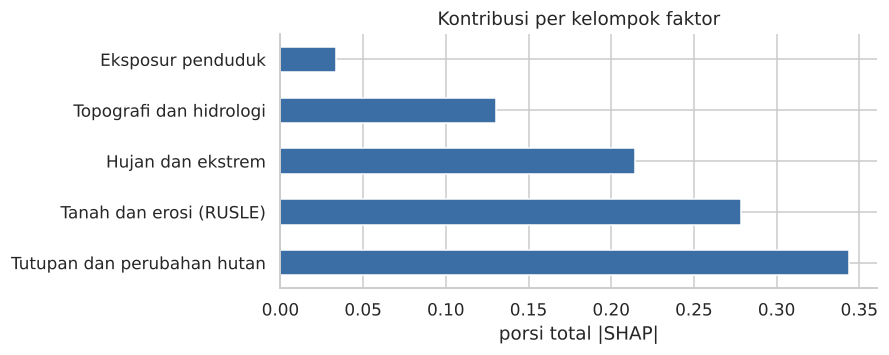

**Interpretasi.** Faktor paling berpengaruh menurut SHAP: `A_rusle_median_tha`, `frak_hutan_curam_2000`, `elev_m`, `ndvi_l1`, `hilang_hutan_curam_frak_l1`. Berdasarkan kelompok, kontribusi terbesar berasal dari **Tutupan dan perubahan hutan** (34%) lalu **Tanah dan erosi (RUSLE)** (28%). SHAP menjelaskan perilaku model, bukan hubungan sebab-akibat, dan untuk fitur statis harus dibaca bersama uji plasebo di atas.

In [31]:
fam = {'Hujan dan ekstrem': ['hujan_mm','rx1day_mm','rx3day_mm','hari_ge50mm','hari_ge100mm','R_t'],
       'Topografi dan hidrologi': ['elev_m','slope_deg','hand_m','frak_hand_lt5m','frak_lereng_curam'],
       'Tutupan dan perubahan hutan': ['treecover2000','frak_hutan_curam_2000','lc_10','lc_40','lc_50','lc_80','hilang_hutan_frak_l1','hilang_hutan_curam_frak_l1','ndvi_l1','water_occ_gt0'],
       'Tanah dan erosi (RUSLE)': ['sand_0_30','clay_0_30','silt_0_30','soc_0_30','K_rusle','LS_rusle','A_rusle_median_tha','frak_erosi_gt60','A_t_tha_l1'],
       'Eksposur penduduk': ['log_kepadatan']}
kel = pd.Series({k: imp[v].sum() for k, v in fam.items()}); kel = (kel / kel.sum()).sort_values(ascending=False)
kel.plot(kind='barh', color='#3b6ea5', figsize=(7, 3)); plt.xlabel('porsi total |SHAP|'); plt.title('Kontribusi per kelompok faktor'); plt.show()
display(Markdown('**Interpretasi.** Faktor paling berpengaruh menurut SHAP: ' + ', '.join(f'`{k}`' for k in imp.index[:5]) + '. Berdasarkan kelompok, kontribusi terbesar berasal dari **' + kel.index[0] + f'** ({kel.iloc[0]:.0%}) lalu **' + kel.index[1] + f'** ({kel.iloc[1]:.0%}). SHAP menjelaskan perilaku model, bukan hubungan sebab-akibat, dan untuk fitur statis harus dibaca bersama uji plasebo di atas.'))

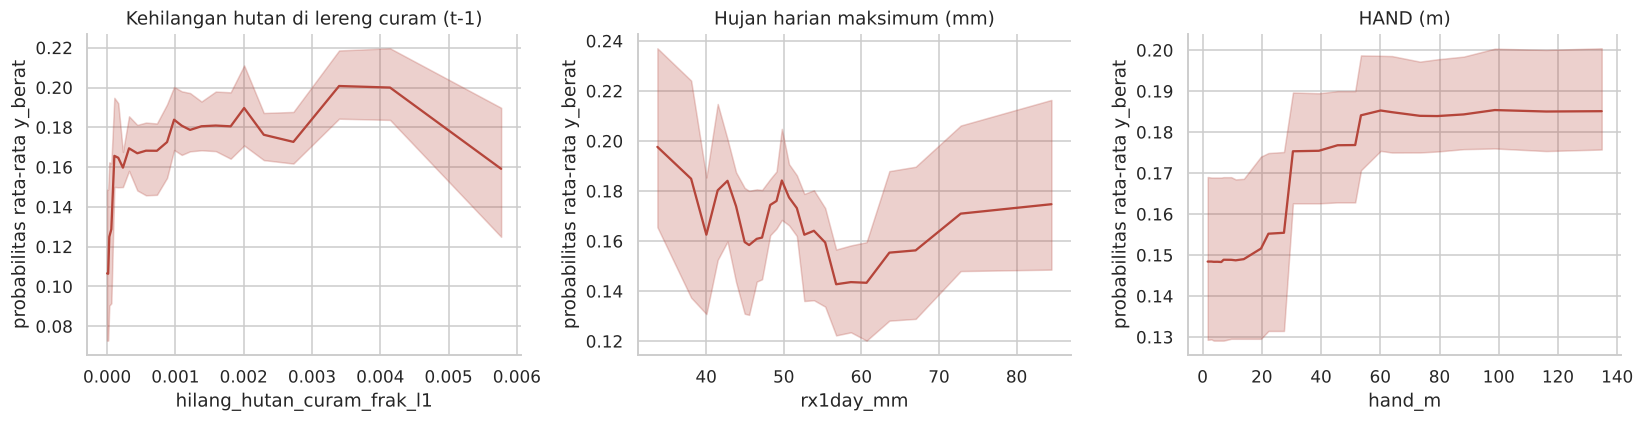

In [32]:
# Analisis ambang: profil dependensi parsial (rata-rata prediksi saat satu fitur divariasikan) dengan pita sebaran antarpohon-bootstrap
def pdp(col, grid, mod, X):
    out = []
    for g_ in grid:
        Z = X[FITUR].copy(); Z[col] = g_; out.append(mod.predict_proba(Z)[:, 1].mean())
    return np.array(out)
boots = []
for b in range(15):
    ix = np.random.default_rng(b).integers(0, len(Xtr), len(Xtr)); boots.append(xgb_model(random_state=b).fit(Xtr.iloc[ix][FITUR], Xtr.iloc[ix].y))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, col, ttl in zip(ax, ['hilang_hutan_curam_frak_l1', 'rx1day_mm', 'hand_m'], ['Kehilangan hutan di lereng curam (t-1)', 'Hujan harian maksimum (mm)', 'HAND (m)']):
    grid = np.quantile(Xtr[col], np.linspace(0.02, 0.98, 25)); P = np.array([pdp(col, grid, b_, Xtr) for b_ in boots])
    a_.plot(grid, P.mean(0), color='#b5453a'); a_.fill_between(grid, np.percentile(P, 10, axis=0), np.percentile(P, 90, axis=0), alpha=.25, color='#b5453a')
    a_.set_title(ttl); a_.set_xlabel(col); a_.set_ylabel('probabilitas rata-rata y_berat')
plt.tight_layout(); plt.show()

In [33]:
display(Markdown('''**Interpretasi.** Kurva di atas menunjukkan bentuk respons model terhadap tiap faktor, dengan pita 10-90% dari 15 model hasil resampling. Hanya segmen kurva yang **berada jauh di dalam pita kepercayaan dan konsisten antar-resampling** yang layak dibaca sebagai pola. Bagian ujung distribusi (data jarang) cenderung tidak stabil. Kurva ini adalah **asosiasi pada model**, dan nilai ambang yang tampak (jika ada) bersifat hipotesis untuk diuji lebih lanjut, bukan ambang kebijakan.'''))

**Interpretasi.** Kurva di atas menunjukkan bentuk respons model terhadap tiap faktor, dengan pita 10-90% dari 15 model hasil resampling. Hanya segmen kurva yang **berada jauh di dalam pita kepercayaan dan konsisten antar-resampling** yang layak dibaca sebagai pola. Bagian ujung distribusi (data jarang) cenderung tidak stabil. Kurva ini adalah **asosiasi pada model**, dan nilai ambang yang tampak (jika ada) bersifat hipotesis untuk diuji lebih lanjut, bukan ambang kebijakan.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

## <a id="s11"></a>11. Metode 2d: Validasi kejadian November 2025 (IMERG dan Sentinel-1)

Model tahunan hanya menangkap kerentanan relatif. Untuk menguji apakah **informasi tingkat kejadian** menjelaskan dampak sesungguhnya, dibandingkan variabel hujan IMERG (22 Nov–5 Des 2025) dan luas genangan Sentinel-1 dengan dampak yang tercatat di DIBI pada **75 kab/kota** di Aceh, Sumatera Utara, dan Sumatera Barat.

,variabel,rho vs terdampak,p-value,rho vs rumah terdampak,rho vs korban jiwa
0,Luas genangan S1 (km2),0.568,0.000,0.457,0.297
1,Genangan di permukiman (km2),0.439,0.000,0.355,0.245
2,Genangan di pertanian (km2),0.498,0.000,0.415,0.290
3,Indikasi longsor S2 (km2),0.209,0.072,0.189,0.270
4,Hujan IMERG kejadian (mm),0.558,0.000,0.456,0.412
5,Hujan CHIRPS kejadian (mm),0.397,0.000,0.280,0.219
6,Intensitas maks IMERG (mm/jam),0.508,0.000,0.393,0.296
7,Hujan tahunan 2025 (mm),-0.104,0.376,-0.065,-0.214
8,Rx1day 2025 (mm),0.464,0.000,0.348,0.182


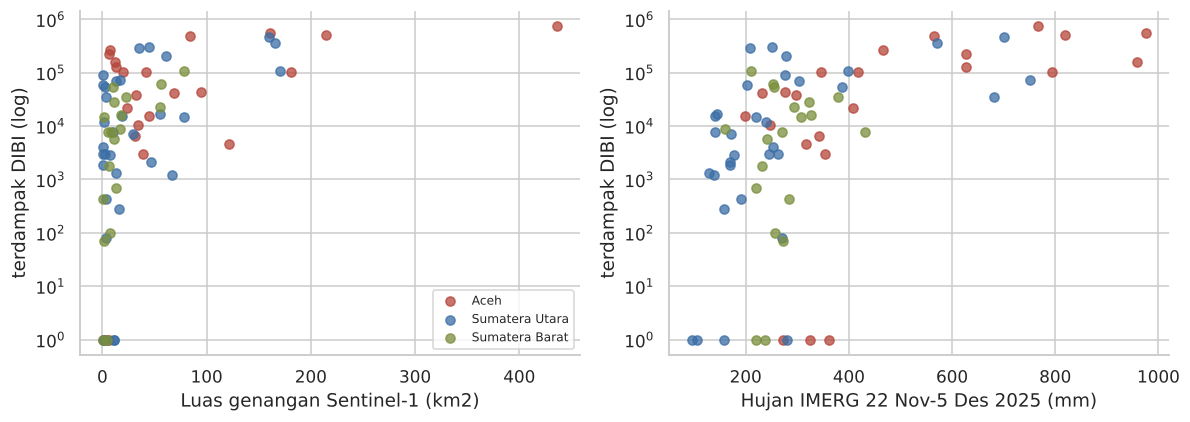

In [34]:
e = m[(m.tahun == 2025) & m.genangan_km2.notna()].copy()
e['rumah_terdampak'] = e.rr_berat + e.rr_sedang + e.rr_ringan + e.terendam
vars_ = {'genangan_km2': 'Luas genangan S1 (km2)', 'genangan_terbangun_km2': 'Genangan di permukiman (km2)', 'genangan_pertanian_km2': 'Genangan di pertanian (km2)',
         'indikasi_longsor_km2': 'Indikasi longsor S2 (km2)', 'ev_imerg_total_mm': 'Hujan IMERG kejadian (mm)', 'ev_chirps_total_mm': 'Hujan CHIRPS kejadian (mm)',
         'ev_imerg_intensitas_maks_mmjam': 'Intensitas maks IMERG (mm/jam)', 'hujan_mm': 'Hujan tahunan 2025 (mm)', 'rx1day_mm': 'Rx1day 2025 (mm)'}
rows = []
for v, lab in vars_.items():
    r1 = spearmanr(e[v], e.terdampak); r2 = spearmanr(e[v], e.rumah_terdampak); r3 = spearmanr(e[v], e.korban_jiwa)
    rows.append([lab, r1[0], r1[1], r2[0], r3[0]])
val = pd.DataFrame(rows, columns=['variabel', 'rho vs terdampak', 'p-value', 'rho vs rumah terdampak', 'rho vs korban jiwa']).round(3)
display(val)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, v, t in zip(ax, ['genangan_km2', 'ev_imerg_total_mm'], ['Luas genangan Sentinel-1 (km2)', 'Hujan IMERG 22 Nov-5 Des 2025 (mm)']):
    for pv, c in zip(e.provinsi.unique(), ['#b5453a', '#3b6ea5', '#7a8f3c']):
        s = e[e.provinsi == pv]; a_.scatter(s[v], s.terdampak + 1, label=pv, alpha=.75, color=c)
    a_.set_yscale('log'); a_.set_xlabel(t); a_.set_ylabel('terdampak DIBI (log)')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [35]:
v_ev = val.set_index('variabel')
display(Markdown(f'''**Interpretasi.** Pada 75 kab/kota terdampak, **hujan IMERG saat kejadian** berkorelasi positif dengan jumlah terdampak (rho = {v_ev.loc['Hujan IMERG kejadian (mm)','rho vs terdampak']:+.2f}) dan **luas genangan Sentinel-1** juga (rho = {v_ev.loc['Luas genangan S1 (km2)','rho vs terdampak']:+.2f}), sedangkan **hujan tahunan 2025** tidak berkorelasi (rho = {v_ev.loc['Hujan tahunan 2025 (mm)','rho vs terdampak']:+.2f}). Pola ini mendukung dua hal: (1) dampak 2025 ditentukan oleh **peristiwa hujan ekstrem jangka pendek**, bukan total hujan tahunan, dan (2) citra radar memberi informasi independen yang sejalan dengan data dampak resmi. Indikasi longsor dari Sentinel-2 korelasinya lebih lemah dan angka luasnya pada beberapa kabupaten tidak masuk akal (mis. ratusan km2), sehingga **tidak dipakai sebagai variabel utama**; deteksi berbasis penurunan NDVI musiman tercampur dengan perubahan fenologi dan awan.'''))

**Interpretasi.** Pada 75 kab/kota terdampak, **hujan IMERG saat kejadian** berkorelasi positif dengan jumlah terdampak (rho = +0.56) dan **luas genangan Sentinel-1** juga (rho = +0.57), sedangkan **hujan tahunan 2025** tidak berkorelasi (rho = -0.10). Pola ini mendukung dua hal: (1) dampak 2025 ditentukan oleh **peristiwa hujan ekstrem jangka pendek**, bukan total hujan tahunan, dan (2) citra radar memberi informasi independen yang sejalan dengan data dampak resmi. Indikasi longsor dari Sentinel-2 korelasinya lebih lemah dan angka luasnya pada beberapa kabupaten tidak masuk akal (mis. ratusan km2), sehingga **tidak dipakai sebagai variabel utama**; deteksi berbasis penurunan NDVI musiman tercampur dengan perubahan fenologi dan awan.

In [36]:
top = e.sort_values('ev_imerg_total_mm', ascending=False)[['nama', 'provinsi', 'ev_imerg_total_mm', 'ev_chirps_total_mm', 'genangan_km2', 'korban_jiwa', 'terdampak']].head(8)
display(top.round(0))
display(Markdown('**Catatan data.** CHIRPS memberi total hujan kejadian yang jauh lebih rendah dari IMERG di kabupaten pesisir timur Aceh dan Sumatera Utara. Satelit IMERG dipakai untuk analisis kejadian karena resolusi waktunya 30 menit dan mampu menangkap intensitas, tetapi keduanya adalah estimasi satelit tanpa koreksi stasiun lokal. Pembandingan dengan data stasiun BMKG disarankan sebagai tindak lanjut.'))

,nama,provinsi,ev_imerg_total_mm,ev_chirps_total_mm,genangan_km2,korban_jiwa,terdampak
153,Kabupaten Aceh Tamiang,Aceh,976.0,307.0,161.0,101.0,558831.0
230,Kota Langsa,Aceh,959.0,311.0,12.0,5.0,161145.0
54,Kabupaten Aceh Timur,Aceh,819.0,333.0,215.0,58.0,498280.0
241,Kota Lhokseumawe,Aceh,793.0,238.0,20.0,5.0,100657.0
120,Kabupaten Aceh Utara,Aceh,766.0,258.0,436.0,251.0,737695.0
582,Kota Medan,Sumatera Utara,751.0,240.0,17.0,12.0,72599.0
395,Kabupaten Langkat,Sumatera Utara,700.0,291.0,160.0,14.0,460892.0
593,Kota Binjai,Sumatera Utara,682.0,219.0,3.0,0.0,35663.0


**Catatan data.** CHIRPS memberi total hujan kejadian yang jauh lebih rendah dari IMERG di kabupaten pesisir timur Aceh dan Sumatera Utara. Satelit IMERG dipakai untuk analisis kejadian karena resolusi waktunya 30 menit dan mampu menangkap intensitas, tetapi keduanya adalah estimasi satelit tanpa koreksi stasiun lokal. Pembandingan dengan data stasiun BMKG disarankan sebagai tindak lanjut.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

---
# Bagian IV · Metode 3: Prioritas pemulihan (R3P)

**Hipotesis H7.** Indeks yang memadukan bahaya, tekanan hulu, eksposur, kerentanan, dan kapasitas akan sejalan dengan dampak 2025 yang tidak dipakai membangunnya.

## <a id="s12"></a>12. Metode 3: Indeks prioritas R3P (TOPSIS) dan uji sensitivitas bobot

Indeks memadukan **bahaya** (probabilitas model), **tekanan lahan hulu** (kehilangan hutan lereng curam di DAS hulu, bagian 7), **eksposur** (penduduk), **kerentanan** (kemiskinan, IPM) dan **kapasitas** (layanan kesehatan dan jaringan jalan). Dengan begitu hasil analisis hulu-hilir masuk langsung ke penentuan prioritas. Aksesibilitas ke fasilitas **belum** dihitung berbasis jaringan karena titik fasilitas resmi tidak tersedia; proksi yang dipakai adalah kepadatan jalan dan rasio fasilitas per 100 ribu penduduk.

In [37]:
# Bahaya: probabilitas rata-rata prediksi model (ensemble XGBoost + logistik) pada fitur 2025 untuk 154 kab/kota
d25 = m[m.tahun == 2025].dropna(subset=FITUR).copy()
lg = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000)).fit(Xtr[FITUR], Xtr.y)
d25['bahaya'] = 0.5 * final.predict_proba(d25[FITUR])[:, 1] + 0.5 * lg.predict_proba(d25[FITUR])[:, 1]
cfg = {  # kriteria: (kolom, arah 'benefit' = makin tinggi makin prioritas)
 'bahaya': ('bahaya', 'benefit'), 'tekanan_hulu': ('loss_curam_hulu_frak', 'benefit'), 'eksposur': ('penduduk', 'benefit'), 'kemiskinan': ('p0', 'benefit'), 'ipm_rendah': ('ipm', 'cost'),
 'rs_kurang': ('rs_per100k', 'cost'), 'puskesmas_kurang': ('puskesmas_per100k', 'cost'), 'jalan_jarang': ('jalan_km_per_km2', 'cost')}
def topsis(df, w, cfg=cfg):
    M = np.column_stack([df[c].values.astype(float) for c, _ in cfg.values()])
    M = (M - M.mean(0)) / M.std(0); W = np.array(w) / np.sum(w)
    V = M * W; ben = np.array([t == 'benefit' for _, t in cfg.values()])
    ideal = np.where(ben, V.max(0), V.min(0)); anti = np.where(ben, V.min(0), V.max(0))
    dp = np.sqrt(((V - ideal) ** 2).sum(1)); dm = np.sqrt(((V - anti) ** 2).sum(1)); return dm / (dp + dm)
w0 = [3, 1, 2, 1, 1, 1, 1, 1]   # urutan: bahaya, tekanan hulu, eksposur, kemiskinan, IPM, RS, puskesmas, jalan
d25['prioritas'] = topsis(d25, w0); d25['peringkat'] = d25.prioritas.rank(ascending=False).astype(int)
display(d25.sort_values('peringkat')[['peringkat', 'nama', 'provinsi', 'prioritas', 'bahaya', 'loss_curam_hulu_frak', 'penduduk', 'p0', 'ipm']].head(15).round(3))

,peringkat,nama,provinsi,prioritas,bahaya,loss_curam_hulu_frak,penduduk,p0,ipm
384,1,Kabupaten Deli Serdang,Sumatera Utara,0.677,0.449,0.005,2078046.0,3.44,76.92
395,2,Kabupaten Langkat,Sumatera Utara,0.573,0.405,0.014,1089969.0,9.04,72.73
1396,3,Kabupaten Tanggamus,Lampung,0.562,0.468,0.024,678021.0,10.28,68.52
120,4,Kabupaten Aceh Utara,Aceh,0.557,0.478,0.023,638957.0,16.11,71.70
142,5,Kabupaten Gayo Lues,Aceh,0.542,0.591,0.063,108672.0,18.30,69.83
65,6,Kabupaten Aceh Tengah,Aceh,0.537,0.551,0.061,229608.0,14.27,75.41
43,7,Kabupaten Aceh Tenggara,Aceh,0.531,0.544,0.042,237910.0,11.99,71.70
714,8,Kabupaten Pasaman,Sumatera Barat,0.521,0.466,0.050,322934.0,6.74,68.89
703,9,Kabupaten Lima Puluh Kota,Sumatera Barat,0.514,0.444,0.042,405714.0,6.92,71.14
1165,10,Kabupaten Ogan Komering Ulu Selatan,Sumatera Selatan,0.509,0.405,0.026,434789.0,9.86,67.65


In [38]:
# Sensitivitas: 1000 vektor bobot acak (Dirichlet), stabilitas peringkat
rng = np.random.default_rng(SEED); base = d25.prioritas.rank(ascending=False)
rhos, ov = [], []; rank_mat = []
top20 = set(d25.nlargest(20, 'prioritas').nama)
for _ in range(1000):
    w = rng.dirichlet(np.ones(len(cfg))); s = pd.Series(topsis(d25, w), index=d25.index); rk = s.rank(ascending=False)
    rhos.append(spearmanr(base, rk)[0]); ov.append(len(top20 & set(d25.loc[s.nlargest(20).index, 'nama'])) / 20); rank_mat.append(rk.values)
rank_mat = np.array(rank_mat); stab = pd.DataFrame({'nama': d25.nama.values, 'median': np.median(rank_mat, 0), 'p5': np.percentile(rank_mat, 5, 0), 'p95': np.percentile(rank_mat, 95, 0)})
print('Spearman peringkat dasar vs acak: median %.2f (p5 %.2f)' % (np.median(rhos), np.percentile(rhos, 5)))
print('Irisan 20 teratas: median %.0f%% (p5 %.0f%%)' % (100*np.median(ov), 100*np.percentile(ov, 5)))
display(stab.sort_values('median').head(10).round(1))

Spearman peringkat dasar vs acak: median 0.65 (p5 0.36)
Irisan 20 teratas: median 40% (p5 10%)


,nama,median,p5,p95
126,Kabupaten Tanggamus,10.0,1.0,42.0
12,Kabupaten Gayo Lues,15.0,1.0,134.0
10,Kabupaten Aceh Utara,15.0,2.0,45.0
35,Kabupaten Langkat,16.0,2.0,72.0
105,Kabupaten Ogan Komering Ulu Selatan,16.0,3.0,49.0
64,Kabupaten Pasaman,19.0,2.0,85.0
133,Kabupaten Pesawaran,19.0,4.0,38.0
127,Kabupaten Lampung Selatan,20.0,2.0,80.0
16,Kabupaten Bener Meriah,20.0,1.0,113.0
5,Kabupaten Aceh Tengah,22.0,2.0,114.0


In [39]:
# Validasi independen: peringkat prioritas vs dampak teramati 2025 (tidak dipakai membangun indeks)
d25['rumah_terdampak'] = d25.rr_berat + d25.rr_sedang + d25.rr_ringan + d25.terendam
d25['infra_rusak'] = d25.sekolah_rusak + d25.faskes_rusak + d25.jembatan_rusak
chk = []
for v in ['korban_jiwa', 'terdampak', 'rumah_terdampak', 'infra_rusak', 'sekolah_rusak']:
    chk.append([v, spearmanr(d25.prioritas, d25[v])[0], spearmanr(d25.prioritas, d25[v])[1]])
chk = pd.DataFrame(chk, columns=['dampak 2025 (DIBI)', 'rho dengan indeks prioritas', 'p-value']).round(3); display(chk)
q = d25.assign(kuartil=pd.qcut(d25.prioritas, 4, labels=['Q1 rendah', 'Q2', 'Q3', 'Q4 tinggi']))
display(q.groupby('kuartil', observed=True)[['korban_jiwa', 'terdampak', 'infra_rusak', 'y']].mean().round(2))
# Ablasi: apakah kriteria tekanan hulu menambah kesesuaian dengan dampak 2025?
cfg_tanpa = {k: v for k, v in cfg.items() if k != 'tekanan_hulu'}
p_tanpa = topsis(d25, [3, 2, 1, 1, 1, 1, 1], cfg_tanpa)
abl_t = pd.DataFrame({v: [spearmanr(d25.prioritas, d25[v])[0], spearmanr(p_tanpa, d25[v])[0]] for v in ['korban_jiwa', 'rr_berat', 'infra_rusak']},
                     index=['dengan tekanan hulu', 'tanpa tekanan hulu']).round(3)
display(abl_t)

,dampak 2025 (DIBI),rho dengan indeks prioritas,p-value
0,korban_jiwa,0.350,0.000
1,terdampak,0.342,0.000
2,rumah_terdampak,0.286,0.000
3,infra_rusak,0.370,0.000
4,sekolah_rusak,0.251,0.002


,korban_jiwa,terdampak,infra_rusak,y
kuartil,,,,
Q1 rendah,1.54,11608.23,8.44,0.18
Q2,1.92,20083.11,3.87,0.29
Q3,1.84,19707.63,8.68,0.26
Q4 tinggi,30.36,128089.95,52.72,0.64


,korban_jiwa,rr_berat,infra_rusak
dengan tekanan hulu,0.350,0.440,0.370
tanpa tekanan hulu,0.338,0.416,0.351


In [40]:
display(Markdown(f'''**Interpretasi.** Peringkat TOPSIS **stabil terhadap perubahan bobot**: korelasi peringkat median dengan peringkat dasar {np.median(rhos):.2f} dan irisan 20 kab/kota teratas median {np.median(ov):.0%}. Terhadap dampak 2025 yang tidak dipakai membangun indeks, korelasi peringkat dengan jumlah terdampak {chk.set_index('dampak 2025 (DIBI)').loc['terdampak','rho dengan indeks prioritas']:+.2f} dan dengan kerusakan infrastruktur kritis {chk.set_index('dampak 2025 (DIBI)').loc['infra_rusak','rho dengan indeks prioritas']:+.2f}. Menambahkan kriteria tekanan hulu mengubah korelasi dengan korban jiwa dari {abl_t.loc['tanpa tekanan hulu','korban_jiwa']:+.2f} menjadi {abl_t.loc['dengan tekanan hulu','korban_jiwa']:+.2f} dan dengan rumah rusak berat dari {abl_t.loc['tanpa tekanan hulu','rr_berat']:+.2f} menjadi {abl_t.loc['dengan tekanan hulu','rr_berat']:+.2f}. Indeks adalah **alat bantu penyusunan prioritas**, bukan penentu tunggal; kuartil prioritas tertinggi harus dibaca bersama kondisi lapangan.'''))

**Interpretasi.** Peringkat TOPSIS **stabil terhadap perubahan bobot**: korelasi peringkat median dengan peringkat dasar 0.65 dan irisan 20 kab/kota teratas median 40%. Terhadap dampak 2025 yang tidak dipakai membangun indeks, korelasi peringkat dengan jumlah terdampak +0.34 dan dengan kerusakan infrastruktur kritis +0.37. Menambahkan kriteria tekanan hulu mengubah korelasi dengan korban jiwa dari +0.34 menjadi +0.35 dan dengan rumah rusak berat dari +0.42 menjadi +0.44. Indeks adalah **alat bantu penyusunan prioritas**, bukan penentu tunggal; kuartil prioritas tertinggi harus dibaca bersama kondisi lapangan.

<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

---
# Penutup

## <a id="s13"></a>13. Keterbatasan, kesimpulan, dan ringkasan angka

**Keterbatasan yang perlu dinyatakan di naskah**
1. **Pencatatan DIBI** bergantung pada pelaporan daerah dan meningkat sejak 2020; sebagian lonjakan kejadian adalah efek pencatatan.
2. **Kemampuan prediksi sedang** (ROC-AUC 0,71 pada uji 2025) dan menurun pada uji blok spasial; model tidak dimaksudkan untuk peramalan operasional.
3. **Penduduk 2015-2019** adalah proyeksi SUPAS dan ada patahan pada 2020 (sensus). Penduduk hanya dipakai sebagai eksposur.
4. **RUSLE**: R dari CHIRPS tanpa koreksi stasiun dan persamaan Renard-Freimund dipakai di luar rentang kalibrasinya (hujan sampai ~4.000 mm), LS dari DEM 90 m cenderung meremehkan lereng sangat curam, C memakai persamaan van der Knijff yang dikalibrasi di Eropa, dan P = 1. Besaran absolut A bersifat indikatif; peringkat yang dipakai. RUSLE mengukur erosi lembar/alur, bukan longsor.
4b. **Tekanan hulu** mengasumsikan seluruh erosi terangkut ke hilir dan memakai HydroBASINS level 8 yang kasar untuk DAS kecil. Kehilangan hutan Hansen juga mencatat bekas longsor, sehingga sebagian asosiasi bisa berarah terbalik; jendela 2015-2025 memuat tahun kejadian, sehingga indikator ini tidak dipakai di model prediktif.
5. **Aksesibilitas berbasis jaringan jalan** belum dihitung karena titik fasilitas resmi tidak tersedia; OSM fasilitas tidak lengkap (cakupan rumah sakit dan puskesmas rendah) sehingga hanya proksi yang dipakai.
6. **Indikasi longsor Sentinel-2** tidak andal sebagai variabel kuantitatif; validasi memerlukan inventarisasi longsor lapangan.
7. Hubungan yang ditemukan bersifat **asosiasi**, bukan sebab-akibat.
8. Analisis kejadian 2025 mencakup tiga provinsi dengan 75 kab/kota; data hujan satelit belum dikoreksi stasiun BMKG.

In [41]:
ringkas = pd.DataFrame({'butir': ['Unit analisis', 'Rentang tahun', 'Sampel model', 'Latih / uji', 'Model terbaik (AUC-PR, uji 2025)', 'ROC-AUC rata-rata blok spasial', 'Korelasi hujan IMERG kejadian vs terdampak (n=75)', 'Kestabilan peringkat prioritas (irisan top-20 median)', 'rho kehilangan hutan lereng curam hulu vs frekuensi y_berat', 'rho erosi RUSLE (median) vs frekuensi y_berat'],
   'nilai': [f'{m.kode_bps.nunique()} kab/kota', '2015-2025', f'{len(d)} kab/kota-tahun', f'{len(Xtr)} / {len(Xte)}', f"{best.model} ({best['AUC-PR']:.2f})", f"{cv['AUC XGBoost'].mean():.2f}", f"{v_ev.loc['Hujan IMERG kejadian (mm)','rho vs terdampak']:+.2f}", f'{np.median(ov):.0%}', f"{h.loc['Kehilangan hutan lereng curam di hulu (fraksi DAS)','rho vs frekuensi y_berat 2015-2024']:+.2f}", f"{h.loc['Erosi RUSLE lokal (median)','rho vs frekuensi y_berat 2015-2024']:+.2f}"]})
display(ringkas)
d25[['kode_bps', 'nama', 'provinsi', 'bahaya', 'loss_curam_hulu_frak', 'prioritas', 'peringkat']].sort_values('peringkat').to_csv('hasil_prioritas_kabkota.csv', index=False)
print('Tersimpan: hasil_prioritas_kabkota.csv')

,butir,nilai
0,Unit analisis,154 kab/kota
1,Rentang tahun,2015-2025
2,Sampel model,1386 kab/kota-tahun
3,Latih / uji,1232 / 154
4,"Model terbaik (AUC-PR, uji 2025)",XGBoost (0.58)
5,ROC-AUC rata-rata blok spasial,0.57
6,Korelasi hujan IMERG kejadian vs terdampak (n=75),+0.56
7,Kestabilan peringkat prioritas (irisan top-20 median),40%
8,rho kehilangan hutan lereng curam hulu vs frekuensi y_berat,+0.53
9,rho erosi RUSLE (median) vs frekuensi y_berat,+0.32


Tersimpan: hasil_prioritas_kabkota.csv


<div style="text-align:right;font-size:90%">[kembali ke daftar isi](#top)</div>

---
**Rujukan metode utama.** Renard dkk. (1997) RUSLE; Renard dan Freimund (1994) faktor R; Williams (1995) EPIC faktor K; Moore dan Burch (1986) faktor LS; van der Knijff dkk. (2000) faktor C; Lehner dan Grill (2013) HydroBASINS; Hansen dkk. (2013) Global Forest Change; Chen dan Guestrin (2016) XGBoost; Lundberg dan Lee (2017) SHAP; Roberts dkk. (2017) validasi silang terstruktur; Hwang dan Yoon (1981) TOPSIS; UNDRR (2015) Kerangka Sendai; UN-SPIDER (2019) pemetaan banjir Sentinel-1.